# Phân tích rủi ro phá sản doanh nghiệp

Xếp hạng doanh nghiệp Mỹ từ BCTC, kiểm tra khả năng chuyển điểm thành xác suất và lập danh sách rà soát theo chi phí. Phụ lục Việt Nam minh họa cách tạo nhãn trên dữ liệu do người chạy cung cấp.

## 0. Cài đặt và import

In [1]:
# Nếu máy chưa có thư viện, bỏ dấu # ở dòng dưới rồi chạy:
# %pip install -q xgboost imbalanced-learn shap kagglehub

import os
import warnings
from pathlib import Path
from sklearn.base import clone
from IPython.display import Markdown
from importlib.metadata import version
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
import kagglehub
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(max((os.cpu_count() or 2) - 1, 1)))
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='IProgress not found')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Hiển thị biểu đồ trực tiếp trong notebook
%matplotlib inline
import seaborn as sns
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             log_loss, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
TRAIN_END, VALID_END = 2011, 2014        # train ≤ 2011 · valid 2012–2014 · test 2015–2018

# Một màu cố định cho mỗi mô hình và mỗi lớp, dùng xuyên suốt notebook
C_MODEL = {'Altman Z': '#7a7a75', 'Logistic': '#2a78d6', 'RandomForest': '#eb6834', 'XGBoost': '#1baf7a', 'Logistic Altman-5': '#9751c4'}
C_ALIVE, C_FAILED = '#2a78d6', '#eb6834'
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'Arial', 'DejaVu Sans'],
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e', 'axes.titlesize': 12,
    'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlecolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e8e7e2', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
    'legend.frameon': False,
})
pd.set_option('display.max_columns', 40, 'display.width', 160)

C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 0.1. Các hàm dùng chung

Toàn bộ hàm xử lý, kiểm tra và xây dựng đặc trưng được định nghĩa ngay dưới đây. Notebook không cần module Python riêng. Chạy ô này trước các phần phân tích.

In [2]:
"""Các phép kiểm tra bổ sung cho báo cáo rủi ro doanh nghiệp.

Mỗi phép fit đều nhận dữ liệu thô và học tiền xử lý trên đúng tập train.
Các kiểm tra hồi cứu không phải bằng chứng về hiệu quả can thiệp nhân quả.
"""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from xgboost import XGBClassifier

ALTMAN_FEATURES = ['wc_to_assets', 're_to_assets', 'ebit_to_assets', 'mve_to_liab', 'asset_turnover']
LAG_FEATURES = ['loss_2y', 'd_roa', 'sales_growth', 'assets_growth', 'market_value_growth', 'roa_sd_3y']
# Năm tỷ số Altman cùng bốn tín hiệu về dòng tiền, quy mô và xu hướng.
COMPACT_FEATURES = ALTMAN_FEATURES + ['ebitda_to_liab', 'ln_market_value', 'market_value_growth', 'roa_sd_3y']
MONOTONE = {'current_ratio': -1, 'debt_to_assets': 1, 'roa': -1, 'mve_to_liab': -1}


class TrainOnlyCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, lower=.01, upper=.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        self.columns_ = list(X.columns)
        self.lo_, self.hi_ = X.quantile(self.lower), X.quantile(self.upper)
        # Cột hoàn toàn thiếu trong train không được học trung vị từ valid/test.
        self.median_ = X.clip(self.lo_, self.hi_, axis=1).median().fillna(0.)
        return self

    def transform(self, X):
        X = X.loc[:, self.columns_]
        return X.clip(self.lo_, self.hi_, axis=1).fillna(self.median_)


def log_odds(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def ranking_metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    both = len(np.unique(y)) == 2
    return {'n': len(y), 'events': int(y.sum()), 'prevalence': y.mean() if len(y) else np.nan,
            'ROC-AUC': roc_auc_score(y, p) if both else np.nan,
            'PR-AUC': average_precision_score(y, p) if both else np.nan}


def fit_partition(model, features, target, train, evaluate, columns=None):
    columns = list(features.columns) if columns is None else columns
    clean = TrainOnlyCleaner().fit(features.loc[train, columns])
    clf = clone(model)
    if isinstance(clf, XGBClassifier):
        yt = target.loc[train]
        clf.set_params(scale_pos_weight=(yt == 0).sum() / max((yt == 1).sum(), 1))
    clf.fit(clean.transform(features.loc[train, columns]), target.loc[train])
    p = clf.predict_proba(clean.transform(features.loc[evaluate, columns]))[:, 1]
    return clf, clean, p


def temporal_oof(features, target, years, models, columns_by_model=None):
    """Dự báo ngoài mẫu chỉ trong train; bỏ 1 năm giữa fit và đánh giá."""
    columns_by_model = columns_by_model or {}
    result = pd.DataFrame(index=features.index, columns=list(models), dtype=float)
    audit = []
    for start, end in ((2005, 2006), (2007, 2008), (2009, 2011)):
        tr, va = years.le(start - 2), years.between(start, end)
        if target.loc[tr].nunique() < 2 or not va.any():
            continue
        for name, model in models.items():
            _, _, p = fit_partition(model, features, target, tr, va, columns_by_model.get(name))
            result.loc[va, name] = log_odds(p)
        audit.append({'train_end': start - 2, 'oof_start': start, 'oof_end': end,
                      'n': int(va.sum()), 'events': int(target.loc[va].sum())})
    return result.dropna(), pd.DataFrame(audit)


def paired_bootstrap(y, predictions, groups, reference, repeats=500, seed=42):
    """Bootstrap công ty, cùng chỉ số cho mọi mô hình; báo chênh lệch ghép cặp."""
    y, groups = np.asarray(y), np.asarray(groups)
    positions = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    rng = np.random.default_rng(seed)
    samples = {k: [] for k in predictions}
    for _ in range(repeats):
        idx = np.concatenate([positions[i] for i in rng.integers(len(positions), size=len(positions))])
        if np.unique(y[idx]).size < 2:
            continue
        for name, p in predictions.items():
            p = np.asarray(p)[idx]
            samples[name].append([roc_auc_score(y[idx], p), average_precision_score(y[idx], p)])
    rows = []
    for name in predictions:
        if name == reference:
            continue
        delta = np.asarray(samples[name]) - np.asarray(samples[reference])
        for j, metric in enumerate(('ROC-AUC', 'PR-AUC')):
            fn = roc_auc_score if j == 0 else average_precision_score
            rows.append({'comparison': f'{name} − {reference}', 'metric': metric,
                         'difference': fn(y, predictions[name]) - fn(y, predictions[reference]),
                         'lo95': np.quantile(delta[:, j], .025), 'hi95': np.quantile(delta[:, j], .975),
                         'bootstrap_valid': len(delta)})
    return pd.DataFrame(rows)


def threshold_counts(y, p):
    """Mọi ngưỡng phân biệt và phương án không cảnh báo; không chia tách điểm bằng nhau."""
    y, p = np.asarray(y, dtype=int), np.asarray(p, dtype=float)
    order = np.argsort(p, kind='stable')
    unique, starts = np.unique(p[order], return_index=True)
    thresholds = np.r_[unique, np.nextafter(unique[-1], np.inf)]
    starts = np.r_[starts, len(y)]
    cum = np.r_[0, y[order].cumsum()]
    fn = cum[starts]
    tp = cum[-1] - fn
    fp = len(y) - starts - tp
    tn = starts - fn
    return pd.DataFrame({'threshold': thresholds, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn})


def review_policy(y, p, review_cost, ead, lgd, effectiveness):
    """Chi phí rà soát mọi cảnh báo + tổn thất còn lại sau can thiệp giả định."""
    if review_cost <= 0 or ead <= 0 or not 0 < lgd <= 1 or not 0 < effectiveness <= 1:
        raise ValueError('Chi phí/EAD dương, LGD và hiệu quả trong (0, 1].')
    table = threshold_counts(y, p)
    loss = ead * lgd
    table['cost'] = (review_cost * (table.tp + table.fp)
                     + loss * table.fn + (1 - effectiveness) * loss * table.tp)
    # Cùng chi phí thì chọn ít cảnh báo hơn, tương ứng ngưỡng cao hơn.
    i = table.index[table.cost.eq(table.cost.min())][-1]
    return float(table.loc[i, 'threshold']), table


def calibration_tables(y, p, years):
    data = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p), 'year': np.asarray(years)})
    data['decile'] = pd.qcut(data.p, 10, duplicates='drop')
    def aggregate(key):
        t = data.groupby(key, observed=True).agg(n=('y', 'size'), events=('y', 'sum'),
                                               observed=('y', 'mean'), predicted=('p', 'mean'))
        t['expected_events'] = t.predicted * t.n
        t['gap'] = t.observed - t.predicted
        return t
    return aggregate('decile'), aggregate('year')


def stability_index(reference, current, bins=10):
    """Biên phân vị cố định trên train; nhóm thiếu riêng; làm trơn 0,5 quan sát."""
    a, b = np.asarray(reference, float), np.asarray(current, float)
    finite = a[np.isfinite(a)]
    if not len(finite):
        return np.nan
    cuts = np.unique(np.quantile(finite, np.linspace(0, 1, bins + 1)))
    edges = np.r_[-np.inf, cuts[1:-1], np.inf]
    def counts(x):
        good = np.isfinite(x)
        return np.r_[np.histogram(x[good], edges)[0], (~good).sum()] + .5
    pa, pb = counts(a), counts(b)
    pa, pb = pa / pa.sum(), pb / pb.sum()
    return float(np.sum((pb - pa) * np.log(pb / pa)))


def rank_order_table(y, p, reference):
    cuts = np.unique(np.quantile(reference, np.linspace(0, 1, 11)))
    bins = np.r_[-np.inf, cuts[1:-1], np.inf]
    data = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    data['risk_bin'] = pd.cut(data.p, bins, labels=False) + 1
    out = data.groupby('risk_bin').agg(n=('y', 'size'), events=('y', 'sum'),
                                      event_rate=('y', 'mean'), mean_pd=('p', 'mean'))
    out['event_share'] = out.events / max(out.events.sum(), 1)
    return out


def vif_table(X):
    z = StandardScaler().fit_transform(X)
    vals = []
    for j in range(z.shape[1]):
        other = np.delete(z, j, axis=1)
        fitted = other @ np.linalg.lstsq(other, z[:, j], rcond=None)[0]
        total = np.square(z[:, j]).sum()
        residual = np.square(z[:, j] - fitted).sum()
        vals.append(total / residual if residual > 1e-12 else np.inf)
    return pd.Series(vals, index=X.columns, name='VIF')

def l1_selected_columns(train, target, columns=None, C=0.1, min_features=5):
    """
    Chọn biến Logistic gọn bằng L1.
    Chỉ học trên train; không dùng valid/test để chọn biến.
    """
    columns = list(train.columns if columns is None else columns)

    cleaner = TrainOnlyCleaner().fit(train[columns])

    selector = Pipeline([
        ("scale", StandardScaler()),
        (
            "clf",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                class_weight="balanced",
                max_iter=5000,
            ),
        ),
    ])

    selector.fit(
        cleaner.transform(train[columns]),
        np.asarray(target),
    )

    coefficients = np.abs(selector.named_steps["clf"].coef_[0])

    selected = [
        column
        for column, coefficient in zip(columns, coefficients)
        if coefficient > 1e-10
    ]

    # Tránh trường hợp L1 loại hết hoặc chỉ còn quá ít biến.
    if len(selected) < min_features:
        selected = [
            columns[index]
            for index in np.argsort(-coefficients)[:min_features]
        ]

    coefficient_table = pd.Series(
        coefficients,
        index=columns,
        name="abs_l1_coefficient",
    ).sort_values(ascending=False)

    return selected, coefficient_table

def compact_columns(train, max_vif=5.):
    cols = [c for c in COMPACT_FEATURES if c in train]
    removed = []
    while len(cols) > 2:
        vif = vif_table(train[cols])
        if vif.max() <= max_vif:
            break
        optional = vif.drop(index=ALTMAN_FEATURES, errors='ignore')
        if optional.empty:
            break
        # Giữ bộ Altman-5 cố định; chỉ lọc phần mở rộng trên train.
        col = optional.idxmax()
        removed.append({'removed': col, 'VIF_before': vif[col]})
        cols.remove(col)
    return cols, vif_table(train[cols]), pd.DataFrame(removed)


def small_candidates(seed=42):
    """Lưới định trước dành riêng backtest; không dùng best_params của mẫu chính."""
    return {
        'Logistic': [Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(
            C=c, class_weight='balanced', max_iter=5000))]) for c in (.1, 1.)],
        'RandomForest': [RandomForestClassifier(n_estimators=100, max_depth=d,
            min_samples_leaf=30, class_weight='balanced', n_jobs=-1, random_state=seed) for d in (10, 18)],
        'XGBoost': [XGBClassifier(n_estimators=100, max_depth=d, min_child_weight=5,
            learning_rate=.05, reg_lambda=5, subsample=.8, colsample_bytree=.8,
            tree_method='hist', n_jobs=-1, random_state=seed) for d in (2, 4)],
    }


def expanding_backtest(features, target, years, seed=42):
    rows, tuning = [], []
    for year in range(2012, 2019):
        # Nhãn t+1: để hở năm year-1; inner valid year-2 cũng có khoảng cách một năm.
        inner_train, inner_valid = years.le(year - 4), years.eq(year - 2)
        outer_train, outer_test = years.le(year - 2), years.eq(year)
        candidates_by_model = small_candidates(seed)
        candidates_by_model['XGBoost đơn điệu'] = [
            clone(model).set_params(monotone_constraints=MONOTONE)
            for model in candidates_by_model['XGBoost']]
        for name, candidates in candidates_by_model.items():
            scores = []
            for j, model in enumerate(candidates):
                _, _, p = fit_partition(model, features, target, inner_train, inner_valid)
                ap = ranking_metrics(target[inner_valid], p)['PR-AUC']
                scores.append(ap)
                tuning.append({'test_year': year, 'model': name, 'candidate': j,
                               'inner_train_end': year-4, 'inner_valid_year': year-2, 'PR-AUC': ap})
            chosen = int(np.nanargmax(scores))
            _, _, p = fit_partition(candidates[chosen], features, target, outer_train, outer_test)
            rows.append({'year': year, 'model': name, 'train_end': year-2, 'candidate': chosen,
                         **ranking_metrics(target[outer_test], p)})
        print(f'Backtest {year}: hoàn tất', flush=True)
    return pd.DataFrame(rows), pd.DataFrame(tuning)


def stress_backtest(features, target, years, seed=42):
    rows = []
    tr, te = years.le(2006), years.between(2007, 2010)
    for name, candidates in small_candidates(seed).items():
        # Chọn tham số trước 2006: train <=2003, inner valid 2005.
        inner = []
        for model in candidates:
            _, _, p = fit_partition(model, features, target, years.le(2003), years.eq(2005))
            inner.append(average_precision_score(target[years.eq(2005)], p))
        _, _, p = fit_partition(candidates[int(np.argmax(inner))], features, target, tr, te)
        yy = years[te].to_numpy()
        for year in range(2007, 2011):
            rows.append({'year': year, 'model': name, 'train_end': 2006,
                         **ranking_metrics(target[te].to_numpy()[yy == year], p[yy == year])})
    return pd.DataFrame(rows)


def forward_vn_panel(reports):
    """X(t); y = lỗ ở t+1 VÀ t+2, HOẶC vốn chủ âm ở t+1/t+2.

    Chỉ giữ cửa sổ có đủ hai năm tương lai liên tiếp; không gán thiếu thành 0.
    """
    d = reports.sort_values(['ticker', 'year']).reset_index(drop=True).copy()
    g = d.groupby('ticker')
    y1, y2 = g.year.shift(-1), g.year.shift(-2)
    valid = y1.eq(d.year + 1) & y2.eq(d.year + 2)
    profit1, profit2 = g.net_profit.shift(-1), g.net_profit.shift(-2)
    equity1, equity2 = g.equity.shift(-1), g.equity.shift(-2)
    valid &= pd.concat([profit1, profit2, equity1, equity2], axis=1).notna().all(axis=1)
    d['label_end'] = d.year + 2
    d['distress_future'] = ((profit1.lt(0) & profit2.lt(0)) | equity1.lt(0) | equity2.lt(0)).astype(int)
    def ratio(a, b):
        return a.div(b.where(b.gt(0))).replace([np.inf, -np.inf], np.nan)
    d['current_ratio'] = ratio(d.current_assets, d.current_liabilities)
    d['debt_to_assets'] = ratio(d.liabilities, d.assets)
    d['roa'] = ratio(d.net_profit, d.assets)
    d['net_margin'] = ratio(d.net_profit, d.sales)
    d['asset_turnover'] = ratio(d.sales, d.assets)
    d['cfo_to_assets'] = ratio(d.operating_cash, d.assets)
    return d.loc[valid].copy()


def two_year_sensitivity(panel, train_end=2011, test_start=2015):
    """Cùng cửa sổ cho nhãn 1/2 năm, không giữ riêng ca dương ở đuôi kiểm duyệt."""
    event_year = panel.last_year + 1
    target = (panel.failed_firm.eq(1) & (event_year-panel.year).between(1, 2)).astype(int)
    followed = panel.last_year.ge(panel.year + 2)
    later_event = panel.failed_firm.eq(1) & event_year.gt(panel.year + 2)
    eligible = target.eq(1) | followed | later_event
    # Theo dõi tối đa đến năm cuối dataset; không tận dụng riêng sự kiện suy ra sau năm đó.
    cutoff = int(panel.year.max()) - 2
    train = panel.year.le(min(train_end - 1, cutoff)) & eligible
    test = panel.year.between(test_start, cutoff) & eligible
    return target, train, test


def write_manifest(data_path, directory, seed, versions):
    directory = Path(directory)
    directory.mkdir(exist_ok=True)
    manifest = {'seed': seed, 'data_sha256': hashlib.sha256(Path(data_path).read_bytes()).hexdigest(),
                'dataset': 'utkarshx27/american-companies-bankruptcy-prediction-dataset',
                'versions': versions}
    (directory / 'run_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')


def safe_div(a, b):
    # Mẫu số gần 0 → NaN, để impute sau thay vì tạo giá trị vô cực
    return (a / b.where(b.abs() > 1e-6)).replace([np.inf, -np.inf], np.nan)

def build_features(panel):
    d = panel.sort_values(['company_name', 'year'])
    firm_id = d['company_name']
    # consecutive: năm t-1 có thật sự là năm liền trước không (loại khoảng trống, vd 2002 → 2006)
    consecutive = d.groupby('company_name')['year'].diff().eq(1)
    # consecutive_3y: 3 dòng t-2, t-1, t là 3 năm liên tiếp (dùng cho độ lệch chuẩn 3 năm)
    consecutive_3y = d.groupby('company_name')['year'].diff(2).eq(2)
    lag = lambda s: s.groupby(firm_id).shift(1).where(consecutive)
    f = pd.DataFrame(index=d.index)
    # Thanh khoản
    f['current_ratio'] = safe_div(d.current_assets, d.current_liab)
    f['quick_ratio'] = safe_div(d.current_assets - d.inventory, d.current_liab)
    f['wc_to_assets'] = safe_div(d.current_assets - d.current_liab, d.total_assets)
    # Đòn bẩy
    f['debt_to_assets'] = safe_div(d.total_liab, d.total_assets)
    f['ltd_to_assets'] = safe_div(d.lt_debt, d.total_assets)
    f['mve_to_liab'] = safe_div(d.market_value, d.total_liab)
    f['neg_equity'] = (d.total_liab > d.total_assets).astype(float)
    # Sinh lời
    f['roa'] = safe_div(d.net_income, d.total_assets)
    f['ebit_to_assets'] = safe_div(d.ebit, d.total_assets)
    f['re_to_assets'] = safe_div(d.retained_earnings, d.total_assets)
    f['net_margin'] = safe_div(d.net_income, d.total_revenue)
    f['gross_margin'] = safe_div(d.gross_profit, d.total_revenue)
    # Lỗ 2 năm liên tiếp; không có năm trước liền kề → NaN (không biết), thay vì mặc định 0
    f['loss_2y'] = ((d.net_income < 0) & (lag(d.net_income) < 0)).astype(float).where(consecutive)
    # Dòng tiền (proxy, vì file không có CFO) và hiệu quả hoạt động
    f['ebitda_to_liab'] = safe_div(d.ebitda, d.total_liab)
    f['asset_turnover'] = safe_div(d.total_revenue, d.total_assets)
    f['inventory_to_assets'] = safe_div(d.inventory, d.total_assets)
    f['receivables_to_assets'] = safe_div(d.receivables, d.total_assets)
    # Quy mô
    f['ln_assets'] = np.log(d.total_assets.clip(lower=1e-3))
    f['ln_market_value'] = np.log(d.market_value.clip(lower=1e-3))
    # Xu hướng (chỉ dùng quá khứ)
    f['d_roa'] = f['roa'] - lag(f['roa'])
    f['sales_growth'] = safe_div(d.total_revenue - lag(d.total_revenue), lag(d.total_revenue).abs())
    f['assets_growth'] = safe_div(d.total_assets - lag(d.total_assets), lag(d.total_assets).abs())
    f['market_value_growth'] = safe_div(d.market_value - lag(d.market_value), lag(d.market_value).abs())
    # Độ lệch chuẩn ROA 3 năm: chỉ tính khi 3 năm liên tiếp (trước đây tính cả qua khoảng trống năm)
    f['roa_sd_3y'] = (f['roa'].groupby(firm_id).rolling(3, min_periods=3).std()
                      .reset_index(level=0, drop=True).where(consecutive_3y))
    return f

## 1. Dữ liệu và từ điển biến

Dữ liệu được tải trực tiếp từ [Kaggle](https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset) bằng `kagglehub`. Ô bên dưới đọc CSV trong thư mục do thư viện trả về, không cần đặt sẵn CSV trong thư mục project. Cần kết nối mạng khi tải lần đầu.

Bước đầu tiên là đặt tên đúng cho 18 biến ẩn danh `X1–X18`, vì mọi hệ số tài chính đều tính từ đây. Đơn vị là triệu USD.

| Cột | Tên | Ý nghĩa | | Cột | Tên | Ý nghĩa |
|---|---|---|---|---|---|---|
| X1 | Current assets | Tài sản ngắn hạn | | X10 | Total assets | Tổng tài sản |
| X2 | Cost of goods sold | Giá vốn hàng bán | | X11 | Total long-term debt | Nợ dài hạn |
| X3 | Depreciation & amortization | Khấu hao | | X12 | EBIT | LN trước lãi vay và thuế |
| X4 | EBITDA | LN trước lãi vay, thuế, khấu hao | | X13 | Gross profit | Lợi nhuận gộp |
| X5 | Inventory | Hàng tồn kho | | X14 | Total current liabilities | Nợ ngắn hạn |
| X6 | Net income | Lợi nhuận ròng | | X15 | Retained earnings | Lợi nhuận giữ lại |
| X7 | Total receivables | Khoản phải thu | | X16 | Total revenue | Tổng doanh thu |
| X8 | Market value | Vốn hóa thị trường | | X17 | Total liabilities | Tổng nợ phải trả |
| X9 | Net sales | Doanh thu thuần | | X18 | Total operating expenses | Tổng chi phí hoạt động |

`status_label` là cột nhãn. `company_name` **không đưa vào mô hình**, chỉ dùng làm khóa để nối các năm của cùng một công ty khi tính biến trễ và chia bootstrap.

In [3]:
# Tải phiên bản mới nhất; thư viện dùng lại dữ liệu đã lưu nếu phiên bản không đổi.
dataset_dir = Path(kagglehub.dataset_download(
    "utkarshx27/american-companies-bankruptcy-prediction-dataset"
))
csv_files = sorted(dataset_dir.rglob('american_bankruptcy.csv'))
if len(csv_files) != 1:
    raise FileNotFoundError(
        f'Cần đúng một tệp american_bankruptcy.csv trong {dataset_dir}, tìm thấy {len(csv_files)}.'
    )
DATA_PATH = csv_files[0]
print('Tệp dữ liệu Kaggle:', DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print('Kích thước:', raw.shape, '| Số công ty:', raw['company_name'].nunique(),
      '| Giai đoạn:', raw['year'].min(), '–', raw['year'].max())
print('Giá trị thiếu:', int(raw.isna().sum().sum()), '| Dòng trùng:', int(raw.duplicated().sum()),
      '| Trùng (công ty, năm):', int(raw.duplicated(['company_name', 'year']).sum()))
print('Tỷ lệ status_label = failed theo dòng:', round((raw['status_label'] == 'failed').mean(), 4))
raw.head()

Tệp dữ liệu Kaggle: C:\Users\HP\.cache\kagglehub\datasets\utkarshx27\american-companies-bankruptcy-prediction-dataset\versions\3\american_bankruptcy.csv
Kích thước: (78682, 21) | Số công ty: 8971 | Giai đoạn: 1999 – 2018
Giá trị thiếu: 0 | Dòng trùng: 0 | Trùng (công ty, năm): 0
Tỷ lệ status_label = failed theo dòng: 0.0663


,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


### Kiểm chứng từ điển biến bằng đồng nhất thức kế toán


In [4]:
VAR_MAP = {'X1': 'current_assets', 'X2': 'cogs', 'X3': 'dep_amort', 'X4': 'ebitda', 'X5': 'inventory',
           'X6': 'net_income', 'X7': 'receivables', 'X8': 'market_value', 'X9': 'net_sales',
           'X10': 'total_assets', 'X11': 'lt_debt', 'X12': 'ebit', 'X13': 'gross_profit',
           'X14': 'current_liab', 'X15': 'retained_earnings', 'X16': 'total_revenue',
           'X17': 'total_liab', 'X18': 'total_opex'}

def holds(left, right, tol=0.01):
    # Tỷ lệ dòng mà hai vế chênh nhau không quá 1%
    return float((np.abs(left - right) <= tol * np.abs(right).clip(lower=1)).mean())

checks = pd.DataFrame([
    ['Từ điển Kaggle', 'Lợi nhuận gộp X13 = Doanh thu X16 − Giá vốn X2', holds(raw.X13, raw.X16 - raw.X2)],
    ['Từ điển Kaggle', 'EBIT X12 = EBITDA X4 − Khấu hao X3', holds(raw.X12, raw.X4 - raw.X3)],
    ['Từ điển Kaggle', 'Chi phí HĐ X18 = Doanh thu X16 − EBITDA X4', holds(raw.X18, raw.X16 - raw.X4)],
    ['Từ điển Kaggle', 'Tài sản ngắn hạn X1 ≤ Tổng tài sản X10', float((raw.X1 <= raw.X10).mean())],
    ['Từ điển Kaggle', 'Nợ ngắn hạn X14 ≤ Tổng nợ X17', float((raw.X14 <= raw.X17).mean())],
    ['Từ điển Kaggle', 'Tổng doanh thu (X16) = Doanh thu thuần (X9)', holds(raw.X16, raw.X9)],
    ['Từ điển Kaggle', 'EBITDA (X4) âm ở tỷ lệ dòng — thực tế phải có DN âm', float((raw.X4 < 0).mean())],
], columns=['Cách đọc', 'Kiểm tra', 'Tỷ lệ dòng thỏa'])
display(checks.style.format({'Tỷ lệ dòng thỏa': '{:.2%}'}).hide(axis='index'))

df = raw.rename(columns=VAR_MAP).sort_values(['company_name', 'year']).reset_index(drop=True)

Cách đọc,Kiểm tra,Tỷ lệ dòng thỏa
Từ điển Kaggle,Lợi nhuận gộp X13 = Doanh thu X16 − Giá vốn X2,100.00%
Từ điển Kaggle,EBIT X12 = EBITDA X4 − Khấu hao X3,100.00%
Từ điển Kaggle,Chi phí HĐ X18 = Doanh thu X16 − EBITDA X4,100.00%
Từ điển Kaggle,Tài sản ngắn hạn X1 ≤ Tổng tài sản X10,100.00%
Từ điển Kaggle,Nợ ngắn hạn X14 ≤ Tổng nợ X17,100.00%
Từ điển Kaggle,Tổng doanh thu (X16) = Doanh thu thuần (X9),100.00%
Từ điển Kaggle,EBITDA (X4) âm ở tỷ lệ dòng — thực tế phải có DN âm,29.25%


**Kết luận.** Bảng mô tả cột thỏa cả năm đồng nhất thức kế toán ở gần 100% số dòng.



## 2. Gán nhãn: dự báo phá sản ở năm t+1


In [5]:
# ── 2.1. Nhãn gốc theo công ty ─────────────────────────────────────────────
# failed_firm = 1 nếu công ty có status_label = 'failed' (đã nộp đơn Chapter 7/11), 0 nếu 'alive'.
df['failed_firm'] = (df['status_label'] == 'failed').astype(int)

# last_year = năm quan sát cuối cùng của mỗi công ty (dùng để xác định năm liền trước khi phá sản)
df['last_year'] = df.groupby('company_name')['year'].transform('max')

firm = df.groupby('company_name').agg( failed=('failed_firm', 'max'), so_nam=('year', 'size'))
# ở TẤT CẢ các năm, kể cả những năm còn cách thời điểm phá sản rất xa.
print('Công ty phá sản:', int(firm['failed'].sum()), '/', len(firm),
      '| Số năm quan sát trung bình của công ty phá sản:', round(firm.loc[firm.failed == 1, 'so_nam'].mean(), 1))

# ── 2.3. Nhãn sự kiện target (phá sản ở năm t+1) ──────────────────────────
# Theo mô tả trên Kaggle, nhãn dương là "năm tài chính TRƯỚC khi nộp đơn phá sản".
# Vì file không lưu nhãn theo năm, ta khôi phục lại: với công ty 'failed', năm quan sát
# cuối cùng (year == last_year) được coi là năm t liền trước khi nộp đơn ở t+1 → target = 1.
# Mọi dòng còn lại (công ty alive, hoặc các năm sớm hơn của công ty failed) → target = 0.
# Hạn chế: công ty 'alive' rời mẫu sớm (M&A, hủy niêm yết tự nguyện) vẫn mang nhãn 0.
df['target'] = ((df['failed_firm'] == 1) & (df['year'] == df['last_year'])).astype(int)

# So sánh tỷ lệ dương của hai cách gán nhãn: status_label (~6,6%) và target t+1 (~0,8%, 609 sự kiện)
# → target hiếm hơn nhiều: dữ liệu mất cân bằng mạnh, cần xử lý ở mục 5 (class weight / SMOTE).
print('\nTỷ lệ dương: status_label =', round(df['failed_firm'].mean(), 4),
      '| target (phá sản t+1) =', round(df['target'].mean(), 4), f"({int(df['target'].sum())} sự kiện)",
      '| Tỷ lệ DN phá sản / tổng số DN:', round(firm['failed'].mean(), 4))

# Xem nhanh toàn bộ bảng sau khi thêm cột failed_firm, last_year, target
print(df[df['company_name'] == 'C_6'])

# Số dòng, số sự kiện phá sản và tỷ lệ phá sản theo từng năm báo cáo
# (dùng để thấy giai đoạn khủng hoảng 2000–2002, 2007–2009 có nhiều sự kiện hơn)
print(df.groupby('year')['target'].agg(['count', 'sum', 'mean']).rename(columns={'count': 'Số dòng', 'sum': 'Số sự kiện', 'mean': 'Tỷ lệ'}))

Công ty phá sản: 609 / 8971 | Số năm quan sát trung bình của công ty phá sản: 8.6

Tỷ lệ dương: status_label = 0.0663 | target (phá sản t+1) = 0.0077 (609 sự kiện) | Tỷ lệ DN phá sản / tổng số DN: 0.0679
      company_name status_label  year  current_assets     cogs  dep_amort  ebitda  inventory  net_income  receivables  market_value  net_sales  total_assets  \
51011          C_6       failed  1999          4424.0  15482.0     1092.0  2248.0      708.0       985.0       1134.0     9932.4150    17730.0       24374.0   
51012          C_6       failed  2000          5179.0  17120.0     1202.0  2583.0      757.0       813.0       1303.0     5958.9688    19703.0       26213.0   
51013          C_6       failed  2001          6540.0  19419.0     1404.0  -456.0      822.0     -1762.0       1414.0     3445.0155    18963.0       32841.0   
51014          C_6       failed  2002          4937.0  18555.0     1366.0 -1256.0      627.0     -3511.0       1481.0     1030.1874    17299.0       30267.0

**Quy ước nhãn dùng trong notebook.** `status_label` không đổi trong suốt lịch sử của công ty, nên một báo cáo năm 2001 cũng mang nhãn *failed* dù công ty đến 2012 mới phá sản. Dùng trực tiếp nhãn đó nghĩa là hỏi "công ty này *rốt cuộc* có phá sản không" — và nhãn của năm cũ chứa thông tin tương lai.

Vì vậy:

> **`target` = 1** nếu năm *t* là năm quan sát cuối của công ty có `status_label = failed` (phá sản ở *t+1*); **`target` = 0** cho mọi dòng còn lại.

Mục 11 đối chiếu kết quả với nhãn `status_label` nguyên bản (`y = status_label == 'failed'`) để đánh giá độ nhạy của mô hình đối với cách gán nhãn. Lưu ý công ty *alive* rời mẫu trước 2018 (mua bán sáp nhập, hủy niêm yết tự nguyện…) vẫn mang nhãn 0 vì file không có lý do rời mẫu.

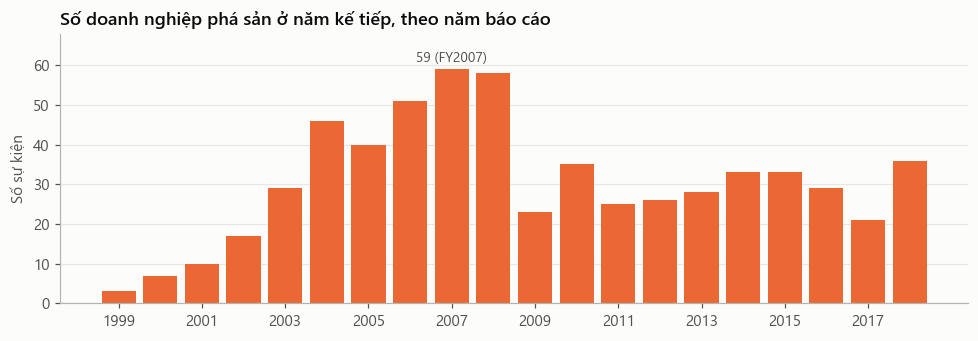

In [6]:
by_year = df.groupby('year')['target'].agg(['sum', 'mean'])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(by_year.index, by_year['sum'], color=C_FAILED, width=0.82)
ax.set_title('Số doanh nghiệp phá sản ở năm kế tiếp, theo năm báo cáo')
ax.set_ylabel('Số sự kiện'); ax.set_xticks(by_year.index[::2]); ax.grid(axis='x', visible=False)
ax.set_ylim(0, by_year['sum'].max() * 1.15)
peak = by_year['sum'].idxmax()
ax.annotate(f"{int(by_year.loc[peak, 'sum'])} (FY{peak})", (peak, by_year.loc[peak, 'sum']), ha='center',
            va='bottom', xytext=(0, 3), textcoords='offset points', color='#52514e', fontsize=9)
plt.tight_layout(); plt.show()

## 3. Đặc trưng tài chính

Biến giá trị tuyệt đối phụ thuộc quy mô, nên được chuyển thành hệ số. Mọi biến xu hướng chỉ nhìn về quá khứ của chính công ty, và chỉ tính khi hai năm liền kề thực sự liên tiếp.

In [7]:
features_raw = build_features(df)
FEATURES = list(features_raw.columns)
print(len(FEATURES), 'đặc trưng')

# ── Báo cáo dữ liệu thiếu ──────────────────────────────────────────────────
# Một số dòng TẤT YẾU không tính được biến xu hướng vì công ty chưa có đủ lịch sử:
#   - Năm đầu tiên của công ty: chưa có năm t-1 → không tính được cả 6 biến xu hướng
#   - Năm thứ hai của công ty: có t-1 nhưng chưa có t-2 → không tính được roa_sd_3y (cần 3 năm)
# Đây là đặc điểm của biến chứ không phải dữ liệu bị thiếu → loại khỏi báo cáo.
# Phần còn lại là thiếu THẬT: công ty có lịch sử nhưng bị đứt quãng năm.
gap = df.groupby('company_name')['year'].diff()          # khoảng cách tới dòng t-1 của cùng công ty
gap2 = df.groupby('company_name')['year'].diff(2)        # khoảng cách tới dòng t-2
first_year = gap.isna()
second_year = gap.eq(1) & gap2.isna()

LAG1_COLS = ['loss_2y', 'd_roa', 'sales_growth', 'assets_growth', 'market_value_growth']
structural = pd.DataFrame(False, index=features_raw.index, columns=FEATURES)   # True = không tính là thiếu
structural[LAG1_COLS] = np.repeat(first_year.values[:, None], len(LAG1_COLS), axis=1)
structural['roa_sd_3y'] = first_year | second_year
miss = features_raw.isna() & ~structural                 # chỉ giữ thiếu thật

print('Không tính là thiếu: năm đầu tiên của công ty:', f'{int(first_year.sum()):,} dòng (cả 6 biến xu hướng)')
print('Không tính là thiếu: năm thứ hai của công ty: ', f'{int(second_year.sum()):,} dòng (chỉ roa_sd_3y)')

# Con số thiếu thực tế (in bằng chữ để đọc được ngay, không cần mở bảng)
n_real = int(miss.any(axis=1).sum())
print(f'\n→ THIẾU THẬT (do đứt quãng năm): {n_real:,} / {len(df):,} dòng ({n_real / len(df):.1%})')
for c in miss.columns[miss.any()]:
    n_miss, n_base = int(miss[c].sum()), int((~structural[c]).sum())
    print(f'   {c:20s}: thiếu {n_miss:>5,} / {n_base:,} dòng được xét ({n_miss / n_base:.1%})')
print('   Các biến còn lại (18 hệ số tỷ lệ): không thiếu dòng nào')

CAUSE = {c: 'Đứt quãng: năm t-1 cách > 1 năm' for c in LAG1_COLS}
CAUSE['roa_sd_3y'] = 'Đứt quãng ở năm t-1 hoặc t-2'
missing_report = pd.DataFrame({
    'Nguyên nhân': [CAUSE.get(c, 'Mẫu số = 0') for c in FEATURES],
    'Số dòng được xét': (~structural).sum(),
    'Số dòng thiếu': miss.sum(),
    'Tỷ lệ thiếu': miss.sum() / (~structural).sum(),
    'Tỷ lệ phá sản khi thiếu': [df.loc[miss[c], 'target'].mean() for c in FEATURES],
    'Tỷ lệ phá sản khi đủ': [df.loc[~structural[c] & ~miss[c], 'target'].mean() for c in FEATURES],
}, index=FEATURES).query('`Số dòng thiếu` > 0')
display(missing_report.style.format({'Tỷ lệ thiếu': '{:.1%}', 'Tỷ lệ phá sản khi thiếu': '{:.2%}',
                                     'Tỷ lệ phá sản khi đủ': '{:.2%}', 'Số dòng thiếu': '{:,}',
                                     'Số dòng được xét': '{:,}'}))

# ── Những dòng bị thiếu nằm ở đâu ─────────────────────────────────────────
where_missing = df[['company_name', 'year']].assign(
    nam_truoc=df.groupby('company_name')['year'].shift(1),
    ly_do=np.select([first_year, second_year, gap > 1, gap2 > 2],
                    ['Năm đầu tiên (không tính là thiếu)',
                     'Năm thứ hai (roa_sd_3y không tính là thiếu)',
                     '1. Đứt quãng: năm t-1 cách > 1 năm',
                     '2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y)'],
                    default='Đủ dữ liệu'),
    so_bien_thieu=miss.sum(axis=1))
missing_rows = where_missing[where_missing['so_bien_thieu'] > 0].copy()
missing_rows['bien_thieu'] = miss.loc[missing_rows.index].apply(lambda r: ', '.join(r.index[r]), axis=1)

# (a) Theo lý do
display(missing_rows.groupby('ly_do').agg(so_dong=('year', 'size'), bien_thieu=('bien_thieu', 'first')))

# (b) Theo năm
display(pd.crosstab(missing_rows['year'], missing_rows['ly_do'], margins=True, margins_name='Tổng'))

# (c) Ví dụ cụ thể: 10 dòng thiếu đầu tiên
display(missing_rows.head(10))

# (d) Toàn bộ lịch sử một công ty có đứt quãng năm, kèm các biến xu hướng (NaN = không tính được)
example = 'C_1046' if 'C_1046' in set(df['company_name']) else missing_rows['company_name'].iloc[0]
trend_cols = ['loss_2y', 'd_roa', 'sales_growth', 'market_value_growth', 'roa_sd_3y']
print('Ví dụ công ty', example)
display(where_missing[df['company_name'] == example].join(features_raw[trend_cols]).round(3))

24 đặc trưng
Không tính là thiếu: năm đầu tiên của công ty: 8,971 dòng (cả 6 biến xu hướng)
Không tính là thiếu: năm thứ hai của công ty:  8,026 dòng (chỉ roa_sd_3y)

→ THIẾU THẬT (do đứt quãng năm): 1,438 / 78,682 dòng (1.8%)
   loss_2y             : thiếu   810 / 69,711 dòng được xét (1.2%)
   d_roa               : thiếu   810 / 69,711 dòng được xét (1.2%)
   sales_growth        : thiếu   810 / 69,711 dòng được xét (1.2%)
   assets_growth       : thiếu   810 / 69,711 dòng được xét (1.2%)
   market_value_growth : thiếu   810 / 69,711 dòng được xét (1.2%)
   roa_sd_3y           : thiếu 1,438 / 61,685 dòng được xét (2.3%)
   Các biến còn lại (18 hệ số tỷ lệ): không thiếu dòng nào


,Nguyên nhân,Số dòng được xét,Số dòng thiếu,Tỷ lệ thiếu,Tỷ lệ phá sản khi thiếu,Tỷ lệ phá sản khi đủ
loss_2y,Đứt quãng: năm t-1 cách > 1 năm,"69,711",810,1.2%,0.62%,0.86%
d_roa,Đứt quãng: năm t-1 cách > 1 năm,"69,711",810,1.2%,0.62%,0.86%
sales_growth,Đứt quãng: năm t-1 cách > 1 năm,"69,711",810,1.2%,0.62%,0.86%
assets_growth,Đứt quãng: năm t-1 cách > 1 năm,"69,711",810,1.2%,0.62%,0.86%
market_value_growth,Đứt quãng: năm t-1 cách > 1 năm,"69,711",810,1.2%,0.62%,0.86%
roa_sd_3y,Đứt quãng ở năm t-1 hoặc t-2,"61,685","1,438",2.3%,0.90%,0.94%


,so_dong,bien_thieu
ly_do,,
1. Đứt quãng: năm t-1 cách > 1 năm,810,"loss_2y, d_roa, sales_growth, assets_growth, m..."
2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),628,roa_sd_3y


ly_do,1. Đứt quãng: năm t-1 cách > 1 năm,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),Tổng
year,,,
2001,37,0,37
2002,55,28,83
2003,57,42,99
2004,60,51,111
2005,53,51,104
2006,68,44,112
2007,37,57,94
2008,51,29,80
2009,51,38,89


,company_name,year,nam_truoc,ly_do,so_bien_thieu,bien_thieu
532,C_1028,2014,2005.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."
533,C_1028,2015,2014.0,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),1,roa_sd_3y
791,C_1046,2006,2002.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."
792,C_1046,2007,2006.0,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),1,roa_sd_3y
799,C_1046,2017,2013.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."
1085,C_107,2006,2004.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."
1086,C_107,2007,2006.0,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),1,roa_sd_3y
1091,C_107,2013,2011.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."
1092,C_107,2014,2013.0,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),1,roa_sd_3y
1277,C_1083,2001,1999.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,"loss_2y, d_roa, sales_growth, assets_growth, m..."


Ví dụ công ty C_1046


,company_name,year,nam_truoc,ly_do,so_bien_thieu,loss_2y,d_roa,sales_growth,market_value_growth,roa_sd_3y
787,C_1046,1999,NaN,Năm đầu tiên (không tính là thiếu),0,NaN,NaN,NaN,NaN,NaN
788,C_1046,2000,1999.0,Năm thứ hai (roa_sd_3y không tính là thiếu),0,0.0,-0.009,4.378,1.167,NaN
789,C_1046,2001,2000.0,Đủ dữ liệu,0,0.0,-0.289,1.121,0.117,0.169
790,C_1046,2002,2001.0,Đủ dữ liệu,0,1.0,0.202,0.085,0.027,0.148
791,C_1046,2006,2002.0,1. Đứt quãng: năm t-1 cách > 1 năm,6,NaN,NaN,NaN,NaN,NaN
792,C_1046,2007,2006.0,2. Đứt quãng ở năm t-2 (chỉ thiếu roa_sd_3y),1,0.0,-0.029,0.574,-0.081,NaN
793,C_1046,2008,2007.0,Đủ dữ liệu,0,0.0,-0.368,0.707,0.181,0.221
794,C_1046,2009,2008.0,Đủ dữ liệu,0,1.0,0.149,-0.607,1.354,0.185
795,C_1046,2010,2009.0,Đủ dữ liệu,0,0.0,0.404,-0.121,-0.080,0.286
796,C_1046,2011,2010.0,Đủ dữ liệu,0,0.0,-0.187,0.464,-0.453,0.202


### Phân tích khám phá: tín hiệu xấu đi thế nào khi tiến gần thời điểm phá sản

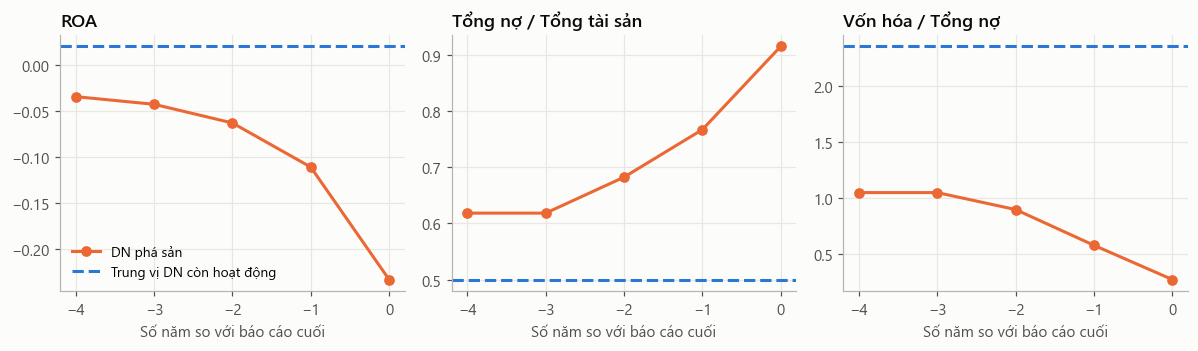

,target = 0,target = 1
current_ratio,1.905,0.930
quick_ratio,1.393,0.606
wc_to_assets,0.211,-0.016
debt_to_assets,0.505,0.914
ltd_to_assets,0.102,0.147
mve_to_liab,2.286,0.269
neg_equity,0.000,0.000
roa,0.018,-0.233
ebit_to_assets,0.048,-0.085
re_to_assets,-0.012,-0.962


In [8]:
rel = df['year'] - df['last_year']
panel_eda = features_raw.assign(rel=rel, failed=df['failed_firm'])
window = panel_eda[(panel_eda.failed == 1) & panel_eda.rel.between(-4, 0)]
alive = panel_eda[panel_eda.failed == 0]
show = {'roa': 'ROA', 'debt_to_assets': 'Tổng nợ / Tổng tài sản', 'mve_to_liab': 'Vốn hóa / Tổng nợ'}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (col, label) in zip(axes, show.items()):
    med = window.groupby('rel')[col].median()
    ax.plot(med.index, med.values, color=C_FAILED, marker='o', markersize=6, label='DN phá sản')
    ax.axhline(alive[col].median(), color=C_ALIVE, ls='--', label='Trung vị DN còn hoạt động')
    ax.set_title(label); ax.set_xticks(range(-4, 1)); ax.set_xlabel('Số năm so với báo cáo cuối')
axes[0].legend(loc='best', fontsize=9)
plt.tight_layout(); plt.show()

compare = pd.DataFrame({'target = 0': features_raw[df.target == 0].median(),
                        'target = 1': features_raw[df.target == 1].median()})
display(compare.round(3))

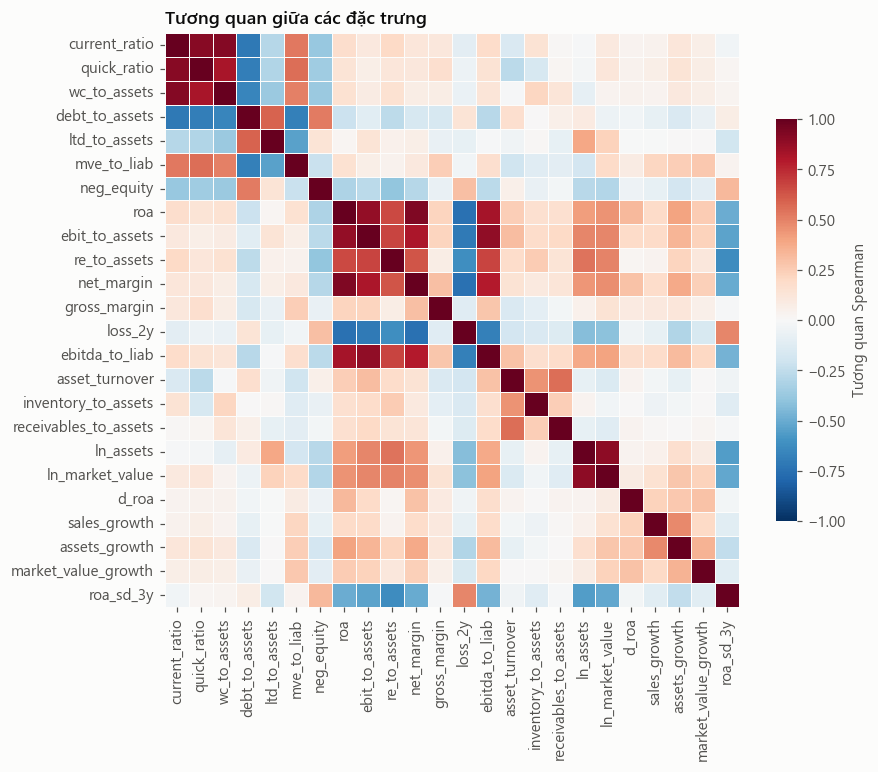

rho
roa            net_margin       0.936
current_ratio  wc_to_assets     0.921
               quick_ratio      0.912
ln_assets      ln_market_value  0.892
ebit_to_assets ebitda_to_liab   0.889
roa            ebit_to_assets   0.881

In [9]:
corr = features_raw.corr(method='spearman')
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, linewidths=.4, linecolor='#fcfcfb',
            cbar_kws={'shrink': .7, 'label': 'Tương quan Spearman'}, ax=ax)
ax.set_title('Tương quan giữa các đặc trưng'); ax.grid(False)
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=np.abs, ascending=False)
display(pairs.head(6).rename('rho').round(3).to_frame())

**Nhận xét.**
- Công ty phá sản xấu đi rõ rệt trong 2–3 năm cuối: ROA trung vị giảm từ khoảng −3% xuống −23%, tổng nợ/tổng tài sản tăng từ 0,62 lên 0,91, vốn hóa/tổng nợ giảm từ khoảng 1,0 xuống 0,27. Đây chính là tín hiệu mà độ trễ t → t+1 khai thác.
- Năm cuối trước phá sản, công ty lỗ 2 năm liên tiếp ở mức trung vị (`loss_2y` = 1), hệ số thanh toán hiện hành 0,93 so với 1,91 ở nhóm còn lại.
- Số vụ cao nhất ở báo cáo FY2007–FY2008 (59 và 58 vụ), đúng giai đoạn khủng hoảng tài chính.
- Nhiều cặp đặc trưng tương quan rất cao (`roa`–`net_margin` 0,94; `current_ratio`–`wc_to_assets` 0,92; `ln_assets`–`ln_market_value` 0,89). Mô hình cây không bị ảnh hưởng nhiều, nhưng hệ số Logistic của các biến này không nên đọc riêng lẻ.

## 4. Chia dữ liệu theo thời gian và làm sạch

| Tập | Năm báo cáo | Vai trò |
|---|---|---|
| Train | 1999–2011 | Fit mô hình, winsorize, trung vị và scaler; tạo dự báo ngoài mẫu theo thời gian để hiệu chuẩn |
| Valid | 2012–2014 | Chọn tham số, cập nhật hệ số chặn và chọn ngưỡng rà soát |
| Test | 2015–2018 | Tập phát triển dùng đối chiếu hồi cứu |

Platt học độ dốc trên các dự báo ngoài mẫu của train. Hệ số chặn được cập nhật theo valid. Các năm 2015–2018 là tập phát triển đã được xem trong quá trình nghiên cứu.

In [10]:
masks = {'train': df['year'] <= TRAIN_END,
         'valid': df['year'].between(TRAIN_END + 1, VALID_END),
         'test': df['year'] > VALID_END}
cleaner = TrainOnlyCleaner().fit(features_raw.loc[masks['train'], FEATURES])
X_all = cleaner.transform(features_raw[FEATURES])
X = {k: X_all[m] for k, m in masks.items()}
y = {k: df.loc[m, 'target'] for k, m in masks.items()}

display(pd.DataFrame({k: {'Số dòng': len(y[k]), 'Số công ty': df.loc[m, 'company_name'].nunique(),
                          'Sự kiện phá sản': int(y[k].sum()), 'Tỷ lệ dương': f'{y[k].mean():.2%}'}
                      for k, m in masks.items()}).T)

,Số dòng,Số công ty,Sự kiện phá sản,Tỷ lệ dương
train,55927,7719,403,0.72%
valid,10473,4074,87,0.83%
test,12282,3700,119,0.97%


### Hai baseline trên năm biến Altman

Z gốc dùng trọng số cố định và được thiết kế cho doanh nghiệp sản xuất niêm yết. Dataset không có mã ngành nên dùng Z như tham chiếu ngoài miền, không coi đây là đối thủ được thiết kế phù hợp cho mọi doanh nghiệp. Bổ sung **Logistic Altman-5**, fit trên cùng năm tỷ số và cùng tập train để tách ảnh hưởng của việc học lại trọng số khỏi việc bổ sung đặc trưng. `C=1` được định trước, không chọn bằng test.

In [11]:
def altman_z(c):
    return 1.2*c['wc_to_assets'] + 1.4*c['re_to_assets'] + 3.3*c['ebit_to_assets'] \
         + 0.6*c['mve_to_liab'] + 1.0*c['asset_turnover']

Z = {k: altman_z(X[k]) for k in X}
zone = pd.cut(Z['test'], [-np.inf, 1.81, 2.99, np.inf], labels=['Nguy cơ (<1.81)', 'Vùng xám', 'An toàn (>2.99)'])
display(pd.crosstab(zone, y['test'], margins=True).rename(columns={0: 'Không phá sản', 1: 'Phá sản'})
        .assign(**{'Tỷ lệ phá sản': lambda t: (t['Phá sản'] / t['All']).map('{:.2%}'.format)}))

altman_logistic = Pipeline([('scale', StandardScaler()),
    ('clf', LogisticRegression(C=1., class_weight='balanced', max_iter=5000))])
altman_logistic.fit(X['train'][ALTMAN_FEATURES], y['train'])

target,Không phá sản,Phá sản,All,Tỷ lệ phá sản
row_0,,,,
Nguy cơ (<1.81),4930,105,5035,2.09%
Vùng xám,1984,7,1991,0.35%
An toàn (>2.99),5249,7,5256,0.13%
All,12163,119,12282,0.97%


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work 

## 5. Xử lý mất cân bằng: class weights so với SMOTE

So sánh 2 phương pháp thực hiện trên tập valid: class weights / `scale_pos_weight`, và SMOTE (chỉ áp dụng trên train). 

In [12]:
# Tính trọng số cho lớp dương (phá sản) để cân bằng dữ liệu mất cân bằng mạnh
pos_weight = float((y['train'] == 0).sum() / (y['train'] == 1).sum())
print('scale_pos_weight =', round(pos_weight, 1))

def make_logit(C=1.0, balanced=True):
    return Pipeline([('scale', StandardScaler()),
                     ('clf', LogisticRegression(C=C, class_weight='balanced' if balanced else None, max_iter=5000))])

def make_rf(max_depth=10, min_samples_leaf=20, balanced=True, n_estimators=400):
    return RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                  class_weight='balanced' if balanced else None,
                                  random_state=RANDOM_STATE, n_jobs=-1)

def make_xgb(spw=1.0, max_depth=3, min_child_weight=5, n_estimators=400):
    return XGBClassifier(n_estimators=n_estimators, learning_rate=0.05, max_depth=max_depth,
                         min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
                         reg_lambda=5.0, scale_pos_weight=spw, eval_metric='aucpr',
                         random_state=RANDOM_STATE, n_jobs=-1)

# SMOTE cần dữ liệu cùng thang đo; chỉ resample trên train
scaler_smote = StandardScaler().fit(X['train'])
X_tr_s = pd.DataFrame(scaler_smote.transform(X['train']), columns=FEATURES)
X_va_s = pd.DataFrame(scaler_smote.transform(X['valid']), columns=FEATURES)
X_bal, y_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr_s, y['train'])

RF_DEMO_TREES = 100
experiments = {
    ('Logistic', 'class_weight'): (make_logit().fit(X['train'], y['train']), X['valid']),
    ('Logistic', 'SMOTE'): (LogisticRegression(max_iter=5000).fit(X_bal, y_bal), X_va_s),
    ('RandomForest', 'class_weight'): (make_rf(n_estimators=RF_DEMO_TREES).fit(X['train'], y['train']), X['valid']),
    ('RandomForest', 'SMOTE'): (make_rf(balanced=False, n_estimators=RF_DEMO_TREES).fit(X_bal, y_bal), X_va_s),   # cây không cần chuẩn hóa, dùng chung X_bal cho gọn
    ('XGBoost', 'scale_pos_weight'): (make_xgb(spw=pos_weight).fit(X['train'], y['train']), X['valid']),
    ('XGBoost', 'SMOTE'): (make_xgb().fit(X_bal, y_bal), X_va_s),
}
rows = []
for (model, method), (clf, X_eval) in experiments.items():
    p = clf.predict_proba(X_eval)[:, 1]
    rows.append({'Mô hình': model, 'Xử lý': method, 'ROC-AUC valid': roc_auc_score(y['valid'], p),
                 'PR-AUC valid': average_precision_score(y['valid'], p)})
display(pd.DataFrame(rows).round(3))

scale_pos_weight = 137.8


,Mô hình,Xử lý,ROC-AUC valid,PR-AUC valid
0,Logistic,class_weight,0.920,0.101
1,Logistic,SMOTE,0.924,0.111
2,RandomForest,class_weight,0.916,0.128
3,RandomForest,SMOTE,0.888,0.078
4,XGBoost,scale_pos_weight,0.901,0.136
5,XGBoost,SMOTE,0.852,0.093


**Cách đọc hai chỉ số.** Tập valid (2012–2014) có 10.473 quan sát, trong đó chỉ 87 ca phá sản (0,0083).

- **ROC-AUC** đo khả năng *xếp hạng*: chọn ngẫu nhiên một công ty sắp phá sản và một công ty khỏe, ROC-AUC là xác suất mô hình chấm công ty sắp phá sản rủi ro hơn. 0,5 là đoán bừa, 1,0 là hoàn hảo; chỉ số không phụ thuộc ngưỡng. ROC-AUC không trực tiếp phản ánh tỷ lệ cảnh báo đúng. Khi sự kiện hiếm, FPR nhỏ vẫn có thể tạo nhiều báo nhầm, nên ROC-AUC cao không bảo đảm Precision cao ở ngưỡng vận hành.
- **PR-AUC** (average precision) chỉ tập trung vào lớp phá sản: khi mô hình lần lượt bắt được các ca phá sản, trung bình bao nhiêu phần trăm công ty bị cảnh báo là phá sản thật. Mức của mô hình đoán bừa bằng tỷ lệ phá sản, khoảng **0,008** chứ không phải 0,5. Vì vậy PR-AUC 0,136 trông thấp nhưng gấp khoảng **16 lần** đoán bừa.
- **Khi hai chỉ số lệch nhau:** Logistic + SMOTE có ROC-AUC cao nhất (0,924) nhưng XGBoost + `scale_pos_weight` có PR-AUC cao nhất (0,136). Logistic xếp hạng tổng thể tốt, còn XGBoost dồn được nhiều ca phá sản thật lên đầu danh sách rủi ro hơn. Hệ thống cảnh báo sớm chỉ rà soát phần đầu danh sách, nên notebook ưu tiên **PR-AUC** khi chọn tham số và mô hình.

**Nhận xét.** SMOTE chỉ nhích nhẹ cho Logistic (PR-AUC 0,111 so với 0,101) nhưng cho PR-AUC thấp hơn ở cả hai mô hình cây. Random Forest 100 cây đạt 0,078 với SMOTE và 0,128 với trọng số lớp. XGBoost đạt lần lượt 0,093 và 0,136. ROC-AUC của hai mô hình cây cũng giảm khi dùng SMOTE. Một cách giải thích: SMOTE nội suy ra các điểm "phá sản nhân tạo" nằm giữa những ca thật, và mô hình cây dễ học thuộc các vùng nhân tạo này thay vì quy luật chung. Ngược lại, Logistic chỉ học một đường biên tuyến tính nên ít bị ảnh hưởng.

Các bước sau dùng **class weights**: đơn giản hơn, không tạo dữ liệu nhân tạo, và tốt nhất hoặc gần tốt nhất ở cả ba mô hình. Hai cách xử lý mất cân bằng của Random Forest đều dùng 100 cây để so sánh trên cùng cấu hình. Mục 6.2 chọn tham số Random Forest với 400 cây.

## 6. Huấn luyện ba mô hình

Tham số của mỗi mô hình được chọn theo PR-AUC trên tập valid, qua hai bước:

1. **6.1 – Quét từng tham số** trên một khoảng rộng, để biết vùng nào đáng thử và tham số nào thực sự quan trọng.
2. **6.2 – Lưới tham số** quanh vùng tốt vừa tìm được, để chọn tổ hợp cuối cùng.

### 6.1. Quét từng tham số

Mỗi lần chỉ thay **một** tham số và giữ các tham số khác ở cấu hình tham chiếu (Random Forest: 100 cây, `max_depth` = 14, `min_samples_leaf` = 30; XGBoost: 200 cây, `max_depth` = 3, `min_child_weight` = 20). Cấu hình này lấy từ một lần chạy sơ bộ, chỉ dùng làm điểm xuất phát.

Cách đọc: nếu đường PR-AUC valid **có đỉnh ở giữa** thì khoảng đã đủ rộng; nếu **tốt nhất nằm ở biên** thì phải mở rộng về phía đó; nếu **đường phẳng** thì tham số không quan trọng. Phép quét số cây Random Forest dùng bốn mốc 25, 50, 100 và 200 trên cùng một rừng. XGBoost quét đến 400 vòng. Mỗi mô hình dùng lại điểm của cấu hình tham chiếu trên cả ba biểu đồ.

In [13]:
REF_RF = dict(n_estimators=RF_DEMO_TREES, max_depth=14, min_samples_leaf=30)
REF_XGB = dict(n_estimators=200, max_depth=3, min_child_weight=20)

scan_train = (X['train'], y['train'])
rf_scan_models, xgb_scan_models = {}, {}
scan_rows = []

def pr_scores(p_train, p_valid):
    return average_precision_score(y['train'], p_train), average_precision_score(y['valid'], p_valid)

def record(model, param, value, scores):
    scan_rows.append({'Mô hình': model, 'Tham số': param, 'Giá trị': 'None' if value is None else str(value),
                      'PR-AUC train': scores[0], 'PR-AUC valid': scores[1]})

# Dùng lại điểm ở mốc tham chiếu cho cả ba đường quét Random Forest.
rf_grow = make_rf(**REF_RF).set_params(warm_start=True)
rf_tree_scores = {}
for n in (25, 50, 100, 200):
    rf_grow.set_params(n_estimators=n).fit(*scan_train)
    rf_tree_scores[n] = pr_scores(rf_grow.predict_proba(X['train'])[:, 1], rf_grow.predict_proba(X['valid'])[:, 1])
rf_ref = (REF_RF['max_depth'], REF_RF['min_samples_leaf'])
rf_scan_models[rf_ref] = rf_grow

for param, values in [('max_depth', (6, 10, 14, 18, None)), ('min_samples_leaf', (1, 30, 60, 100))]:
    for value in values:
        params = {**REF_RF, param: value}
        key = (params['max_depth'], params['min_samples_leaf'])
        if key == rf_ref:
            scores = rf_tree_scores[REF_RF['n_estimators']]
        else:
            clf = make_rf(**params).fit(*scan_train)
            scores = pr_scores(clf.predict_proba(X['train'])[:, 1], clf.predict_proba(X['valid'])[:, 1])
            if key[0] in (14, 18, None) and key[1] in (30, 60, 100):
                rf_scan_models[key] = clf
        record('RandomForest', param, value, scores)
for n, scores in rf_tree_scores.items():
    record('RandomForest', 'n_estimators', n, scores)

# Một lượt 400 vòng cung cấp cả điểm tham chiếu 200 vòng và đường quét số vòng.
xgb_long = make_xgb(spw=pos_weight, **{**REF_XGB, 'n_estimators': 400}).fit(*scan_train)
xgb_tree_scores = {}
for n in (25, 100, 150, 200, 300, 400):
    xgb_tree_scores[n] = pr_scores(xgb_long.predict_proba(X['train'], iteration_range=(0, n))[:, 1],
                                   xgb_long.predict_proba(X['valid'], iteration_range=(0, n))[:, 1])
xgb_ref = (REF_XGB['max_depth'], REF_XGB['min_child_weight'])
xgb_scan_models[xgb_ref] = xgb_long

for param, values in [('max_depth', (2, 3, 4, 6)), ('min_child_weight', (1, 5, 20, 150))]:
    for value in values:
        params = {**REF_XGB, param: value}
        key = (params['max_depth'], params['min_child_weight'])
        if key == xgb_ref:
            scores = xgb_tree_scores[REF_XGB['n_estimators']]
        else:
            clf = make_xgb(spw=pos_weight, **params).fit(*scan_train)
            scores = pr_scores(clf.predict_proba(X['train'])[:, 1], clf.predict_proba(X['valid'])[:, 1])
            xgb_scan_models[key] = clf
        record('XGBoost', param, value, scores)
for n, scores in xgb_tree_scores.items():
    record('XGBoost', 'n_estimators', n, scores)

scan_df = pd.DataFrame(scan_rows)
for (model, param), g in scan_df.groupby(['Mô hình', 'Tham số'], sort=False):
    print(f'{model} · {param}')
    display(g.set_index('Giá trị')[['PR-AUC train', 'PR-AUC valid']].T.round(3))


RandomForest · max_depth


Giá trị,6,10,14,18,None
PR-AUC train,0.151,0.327,0.547,0.622,0.635
PR-AUC valid,0.121,0.151,0.142,0.174,0.166


RandomForest · min_samples_leaf


Giá trị,1,30,60,100
PR-AUC train,0.524,0.547,0.362,0.250
PR-AUC valid,0.114,0.142,0.146,0.143


RandomForest · n_estimators


Giá trị,25,50,100,200
PR-AUC train,0.494,0.555,0.547,0.549
PR-AUC valid,0.120,0.131,0.142,0.145


... (2 outputs left out)

XGBoost · min_child_weight


Giá trị,1,5,20,150
PR-AUC train,0.161,0.158,0.167,0.153
PR-AUC valid,0.154,0.156,0.167,0.167


XGBoost · n_estimators


Giá trị,25,100,150,200,300,400
PR-AUC train,0.083,0.129,0.148,0.167,0.204,0.253
PR-AUC valid,0.121,0.162,0.166,0.167,0.151,0.128


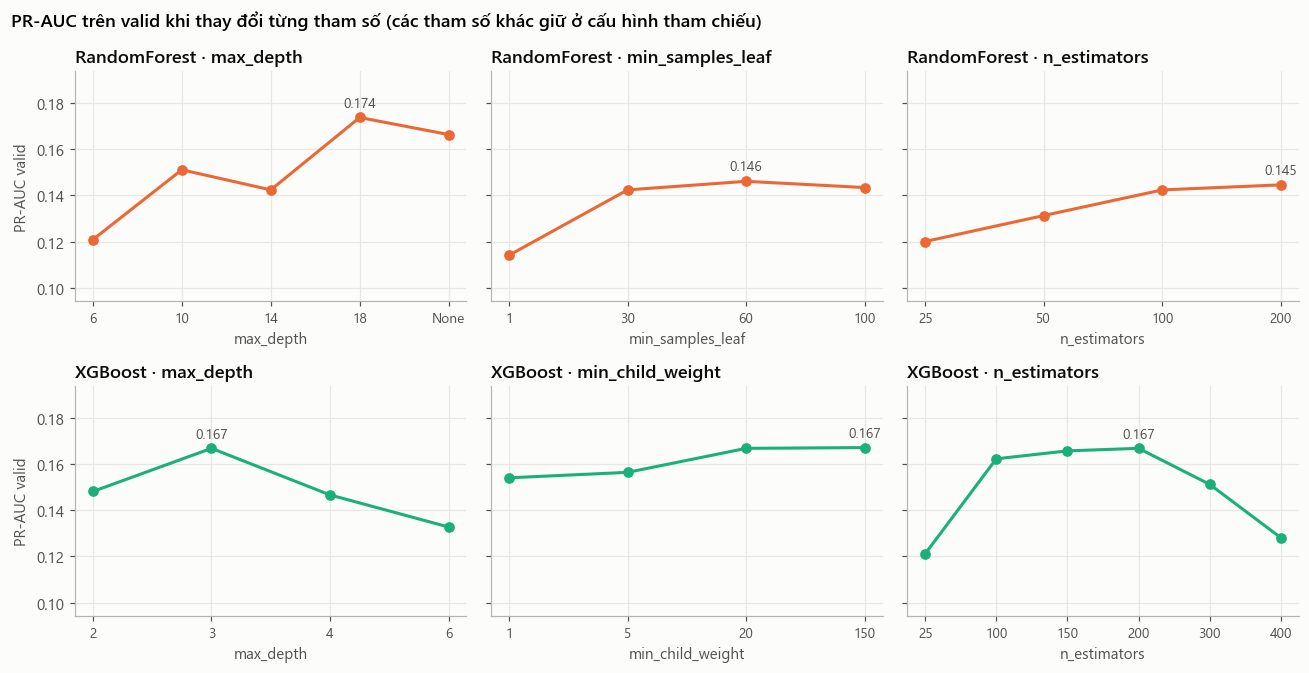

In [14]:
panels = [('RandomForest', 'max_depth'), ('RandomForest', 'min_samples_leaf'), ('RandomForest', 'n_estimators'),
          ('XGBoost', 'max_depth'), ('XGBoost', 'min_child_weight'), ('XGBoost', 'n_estimators')]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharey=True)
for ax, (model, param) in zip(axes.ravel(), panels):
    g = scan_df[(scan_df['Mô hình'] == model) & (scan_df['Tham số'] == param)].reset_index(drop=True)
    xs = np.arange(len(g))
    ax.plot(xs, g['PR-AUC valid'], color=C_MODEL[model], marker='o', markersize=6)
    best = int(g['PR-AUC valid'].idxmax())
    ax.annotate(f"{g.loc[best, 'PR-AUC valid']:.3f}", (best, g.loc[best, 'PR-AUC valid']), xytext=(0, 7),
                textcoords='offset points', ha='center', fontsize=9, color='#52514e')
    ax.set_xticks(xs, g['Giá trị'], fontsize=9)
    ax.set_title(f'{model} · {param}')
    ax.set_xlabel(param)
for ax in axes[:, 0]:
    ax.set_ylabel('PR-AUC valid')
axes[0, 0].set_ylim(scan_df['PR-AUC valid'].min() - 0.02, scan_df['PR-AUC valid'].max() + 0.02)
fig.suptitle('PR-AUC trên valid khi thay đổi từng tham số (các tham số khác giữ ở cấu hình tham chiếu)',
             x=0.01, ha='left', fontsize=12, fontweight='semibold')
plt.tight_layout(); plt.show()

**Nhận xét.**
- **Random Forest · `max_depth`:** với 100 cây và ít nhất 30 quan sát mỗi lá, độ sâu 18 cho PR-AUC valid cao nhất (0,174). Cấu hình không giới hạn đạt 0,166. Mục 6.2 kiểm tra các mức 14, 18 và không giới hạn với rừng 400 cây.
- **Random Forest · `min_samples_leaf`:** ở độ sâu 14, lá tối thiểu 60 quan sát cho PR-AUC valid cao nhất (0,146). Các mức 30 và 100 đạt 0,142 và 0,143, còn lá chỉ 1 quan sát đạt 0,114. Mục 6.2 kết hợp ba mức 30, 60 và 100 với từng độ sâu.
- **Random Forest · `n_estimators`:** khi tăng từ 25 lên 200 cây, PR-AUC valid tăng từ 0,120 lên 0,145. Hai mốc 100 và 200 cây đạt 0,142 và 0,145. Mục 6.2 dùng cấu hình 400 cây để chọn độ sâu và kích thước lá.
- **XGBoost · `max_depth`:** đỉnh rõ ở 3 (0,167). Ở độ sâu 6, PR-AUC train tăng lên 0,759 còn valid giảm xuống 0,133. Lưới giữ **2, 3, 4**.
- **XGBoost · `min_child_weight`:** gần như phẳng (0,154–0,167). Với cây nông, tham số này hầu như không ảnh hưởng → giữ **5 và 20**.
- **XGBoost · `n_estimators`:** đỉnh ở khoảng 100–200 cây (0,162–0,167). Từ 300 đến 400 vòng, PR-AUC train tăng từ 0,204 lên 0,253, còn valid giảm từ 0,151 xuống 0,128. Lưới giữ **100, 150, 200** vòng.

### 6.2. Lưới tham số

Dựa trên kết quả quét, lưới được đặt quanh vùng tốt: Random Forest mở rộng sang cây sâu hơn và lá lớn hơn; XGBoost giữ cây nông và dùng ít cây hơn. Valid chỉ có 87 ca phá sản, nên lưới vẫn được giữ nhỏ để tránh chọn trúng một tổ hợp "may mắn".

Khi tập train vẫn là tập dùng ở mục 6.1, Random Forest bổ sung cây cho các rừng có cùng độ sâu và kích thước lá. XGBoost dùng một mô hình cho mỗi cặp độ sâu và `min_child_weight` để chấm đủ ba mốc số vòng.


In [15]:
from copy import deepcopy

# Mục này cũng chạy được khi bỏ qua ô quét hoặc vừa tạo lại tập train.
scan_inputs = globals().get('scan_train')
reuse_scan = scan_inputs is not None and scan_inputs[0] is X['train'] and scan_inputs[1] is y['train']
rf_candidates = rf_scan_models if reuse_scan else {}
xgb_candidates = xgb_scan_models.copy() if reuse_scan else {}

def fit_and_score_candidate(name, factory, params):
    if name == 'RandomForest':
        key = (params['max_depth'], params['min_samples_leaf'])
        if key in rf_candidates:
            clf = deepcopy(rf_candidates[key])
            clf.set_params(warm_start=True, n_estimators=factory(**params).n_estimators).fit(X['train'], y['train'])
            return clf, clf.predict_proba(X['valid'])[:, 1]

    if name == 'XGBoost':
        key = (params['max_depth'], params['min_child_weight'])
        if key not in xgb_candidates:
            xgb_candidates[key] = factory(**{**params, 'n_estimators': 200}).fit(X['train'], y['train'])
        clf = xgb_candidates[key]
        p = clf.predict_proba(X['valid'], iteration_range=(0, params['n_estimators']))[:, 1]
        return clf, p

    clf = factory(**params).fit(X['train'], y['train'])
    return clf, clf.predict_proba(X['valid'])[:, 1]

def search(name, factory, grid):
    results = []
    for params in grid:
        clf, p = fit_and_score_candidate(name, factory, params)
        results.append({**{k: str(v) for k, v in params.items()},
                        'PR-AUC': average_precision_score(y['valid'], p),
                        'ROC-AUC': roc_auc_score(y['valid'], p), '_clf': clf, '_params': params})
    return pd.DataFrame(results).sort_values('PR-AUC', ascending=False).reset_index(drop=True)

grids = {
    'Logistic': (make_logit, [{'C': c} for c in (0.01, 0.1, 1, 10)]),
    'RandomForest': (make_rf, [{'max_depth': d, 'min_samples_leaf': l} for d in (14, 18, None) for l in (30, 60, 100)]),
    'XGBoost': (lambda **kw: make_xgb(spw=pos_weight, **kw),
                [{'max_depth': d, 'min_child_weight': m, 'n_estimators': n}
                 for d in (2, 3, 4) for m in (5, 20) for n in (100, 150, 200)]),
}
models, best_params = {}, {}
for name, (factory, grid) in grids.items():
    res = search(name, factory, grid)
    models[name] = res.loc[0, '_clf']
    best_params[name] = res.loc[0, '_params']
    if name == 'XGBoost' and models[name].n_estimators != best_params[name]['n_estimators']:
        # Huấn luyện đúng số vòng đã chọn để predict_proba và SHAP dùng cùng mô hình.
        models[name] = factory(**best_params[name]).fit(X['train'], y['train'])
    print(name); display(res.drop(columns=['_clf', '_params']).head(5).round(3))

raw_prob = {name: {k: clf.predict_proba(X[k])[:, 1] for k in X} for name, clf in models.items()}

import json
(RESULTS / 'selected_parameters.json').write_text(json.dumps(best_params, indent=2), encoding='utf-8')


Logistic


,C,PR-AUC,ROC-AUC
0,1,0.101,0.92
1,10,0.101,0.92
2,0.1,0.100,0.92
3,0.01,0.098,0.92


RandomForest


,max_depth,min_samples_leaf,PR-AUC,ROC-AUC
0,18,30,0.154,0.911
1,None,30,0.153,0.910
2,14,30,0.151,0.913
3,None,60,0.150,0.912
4,18,60,0.149,0.913


XGBoost


,max_depth,min_child_weight,n_estimators,PR-AUC,ROC-AUC
0,4,5,100,0.173,0.912
1,3,20,200,0.167,0.908
2,3,20,150,0.166,0.912
3,2,5,150,0.165,0.914
4,2,5,100,0.164,0.912


198

**Các tham số được tinh chỉnh là gì?** Đây là các **siêu tham số** (hyperparameter): mô hình không tự học được chúng từ dữ liệu, nên phải thử nhiều giá trị và chọn theo tập valid. Mọi tham số dưới đây đều điều chỉnh **độ phức tạp** của mô hình, tức đánh đổi giữa *chưa khớp* (quá đơn giản, bỏ sót quy luật) và *quá khớp* (học thuộc cả nhiễu của train).

| Mô hình | Tham số | Ý nghĩa | Tăng giá trị thì mô hình… |
|---|---|---|---|
| Logistic | `C` | Nghịch đảo mức phạt điều chuẩn L2: mô hình tối thiểu ½·Σβ² + C·(log-loss) | **phức tạp hơn**: phạt yếu đi, hệ số β được tự do lớn hơn |
| Random Forest | `max_depth` | Số tầng tối đa của mỗi cây, tức số câu hỏi "nếu–thì" nối tiếp | **phức tạp hơn**: chia được nhóm nhỏ và tinh hơn |
| Random Forest | `min_samples_leaf` | Số quan sát tối thiểu trong mỗi lá | **đơn giản hơn**: không được tạo lá chỉ chứa vài công ty |
| XGBoost | `max_depth` | Số tầng tối đa của mỗi cây (cây boosting thường nông, 2–6) | **phức tạp hơn**: mỗi cây nắm được tương tác giữa nhiều biến hơn |
| XGBoost | `min_child_weight` | Tổng Hessian tối thiểu trong một nút con; phụ thuộc xác suất và trọng số mẫu, không phải số ca phá sản | **đơn giản hơn**: hạn chế tách nhánh có tổng Hessian nhỏ |
| XGBoost | `n_estimators` | Số cây nối tiếp nhau, mỗi cây sửa lỗi của các cây trước (tốc độ học cố định 0,05) | **phức tạp hơn**: càng nhiều cây càng bám sát train |

**Vì sao chúng ảnh hưởng tới PR-AUC và ROC-AUC trên valid?** Mô hình quá đơn giản thì xếp hạng thô, các ca phá sản lẫn vào nhóm công ty khỏe, nên cả hai chỉ số đều thấp. Mô hình quá phức tạp thì học thuộc các ca phá sản cụ thể trong 1999–2011, điểm train rất cao nhưng không tổng quát hóa sang 2012–2014, nên điểm valid giảm. Điểm tốt nhất nằm ở giữa, và chỉ tìm được bằng cách thử.

**PR-AUC nhạy hơn ROC-AUC.** ROC-AUC đo thứ hạng trên toàn bộ hơn 10 nghìn quan sát valid, nên đổi tham số chỉ làm nó nhích vài phần nghìn. PR-AUC phụ thuộc chủ yếu vào việc vài chục công ty đứng đầu danh sách có phải ca phá sản thật hay không, nên thay đổi ở đúng nhóm này làm PR-AUC đổi rõ. Đây cũng là lý do notebook chọn tham số theo PR-AUC.

**Đọc kết quả ở bảng trên (top 5 mỗi mô hình).**
- **Logistic:** cả bốn giá trị `C` cho PR-AUC gần như bằng nhau (0,098–0,101), ROC-AUC đều 0,92. Với khoảng 56 nghìn quan sát và 24 đặc trưng, phần sai số trên dữ liệu áp đảo phần phạt, nên điều chuẩn gần như không có tác dụng. Mô hình tuyến tính vốn đã đơn giản nên không có gì nhiều để "kìm" lại.
- **Random Forest:** tốt nhất là `max_depth` = 18, `min_samples_leaf` = 30 (PR-AUC 0,154); cây không giới hạn độ sâu (0,153) và độ sâu 14 cũ (0,151) bám rất sát. ROC-AUC lại hơi giảm khi cây sâu hơn (0,913 → 0,911): cây sâu tách nhóm rủi ro cao nhất tinh hơn, có lợi cho đầu danh sách (PR-AUC), nhưng thứ hạng ở phần giữa nhiễu hơn một chút. Hai chỉ số không phải lúc nào cũng cùng chiều.
- **XGBoost:** tốt nhất là `max_depth` = 4, `min_child_weight` = 5, **100 cây** (PR-AUC 0,173), tiếp theo là cấu hình tham chiếu độ sâu 3 với 200 cây (0,167). Cây sâu hơn học nhanh hơn nên cần ít cây hơn: số cây và độ sâu phải được chọn cùng nhau. Ba trong năm tổ hợp đầu có ROC-AUC khác nhau rất ít (0,908–0,914) trong khi PR-AUC chênh rõ hơn.

**Lưu ý về nhiễu.** Phần quét độ sâu và kích thước lá dùng 100 cây để minh họa, còn lưới chọn tham số dùng 400 cây. Tập valid chỉ có 87 ca phá sản, nên vài thay đổi ở đầu danh sách xếp hạng có thể làm PR-AUC và thứ tự các cấu hình thay đổi. Ô kế tiếp đối chiếu điểm train và valid.

In [16]:
# Kiểm tra quá khớp: khoảng cách train → valid
display(pd.DataFrame({name: {f'ROC-AUC {k}': roc_auc_score(y[k], raw_prob[name][k]) for k in ('train', 'valid')}
                            | {f'PR-AUC {k}': average_precision_score(y[k], raw_prob[name][k]) for k in ('train', 'valid')}
                      for name in models}).T.round(3))

,ROC-AUC train,ROC-AUC valid,PR-AUC train,PR-AUC valid
Logistic,0.858,0.920,0.048,0.101
RandomForest,0.997,0.911,0.623,0.154
XGBoost,0.961,0.912,0.195,0.173


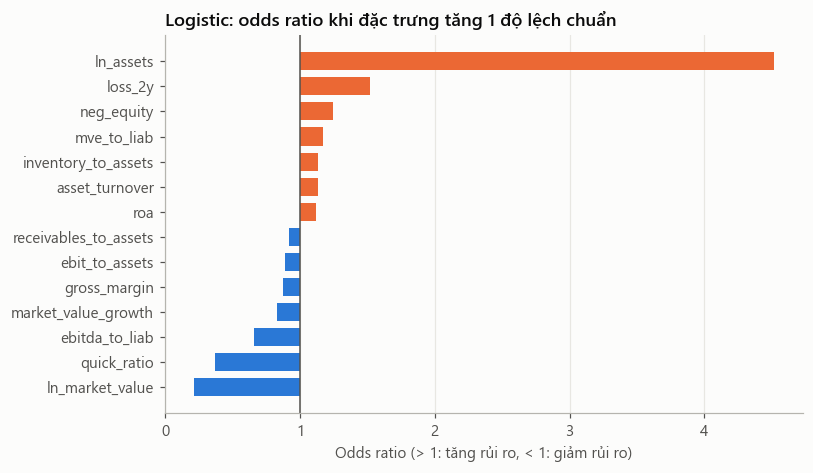

In [17]:
# Hệ số Logistic dưới dạng odds ratio trên 1 độ lệch chuẩn
coef = pd.Series(models['Logistic'].named_steps['clf'].coef_[0], index=FEATURES)
odds = np.exp(coef).sort_values()
top = pd.concat([odds.head(7), odds.tail(7)])
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(top.index, top.values - 1, left=1, color=[C_ALIVE if v < 1 else C_FAILED for v in top.values], height=.72)
ax.axvline(1, color='#52514e', lw=1); ax.grid(axis='y', visible=False)
ax.set_title('Logistic: odds ratio khi đặc trưng tăng 1 độ lệch chuẩn')
ax.set_xlabel('Odds ratio (> 1: tăng rủi ro, < 1: giảm rủi ro)')
plt.tight_layout(); plt.show()

**Diễn giải khoảng cách train–valid.** Random Forest có PR-AUC train cao hơn valid nhiều, cho thấy cần theo dõi khả năng tổng quát hóa; không loại hay giữ mô hình chỉ từ độ chênh này. XGBoost với ít vòng có độ chênh nhỏ hơn trên lần chia hiện tại.

ROC-AUC valid cao hơn train của Logistic không chứng minh mô hình không quá khớp: hai giai đoạn có thành phần doanh nghiệp và điều kiện vĩ mô khác nhau. Backtest theo năm ở mục 13 bổ sung bằng chứng về biến động theo thời gian.

Các hệ số Logistic chịu ảnh hưởng của biến tương quan. Odds ratio là liên hệ có điều kiện trong mô hình có điều chuẩn, không phải tác động nhân quả; dùng thêm Logistic gọn và VIF ở mục 13.2 để kiểm tra độ nhạy.

## 7. Chọn champion và hiệu chuẩn

Quy tắc chọn mô hình được định trước như sau:

1. Dùng backtest cuốn chiếu theo năm làm bằng chứng chính.
2. Nếu XGBoost có chênh lệch PR-AUC trung bình dương so với Logistic và kiểm định dấu hai phía trên các chênh lệch từng năm có `p < 0,05`, chọn XGBoost.
3. Nếu không đạt cả hai điều kiện trên, chọn Logistic đầy đủ làm champion vì đơn giản và dễ giải thích hơn.
4. XGBoost đơn điệu được giữ làm challenger có ràng buộc giải thích được.
5. Random Forest là mô hình đối chứng.

Không chọn mô hình dựa trên một điểm test đơn lẻ. Giai đoạn 2015–2018 đã được xem trong quá trình nghiên cứu nên được gọi là **tập phát triển hồi cứu**, không phải holdout xác nhận độc lập. Quy tắc trên cần được khóa trước khi đánh giá một giai đoạn mới.

Hiệu chuẩn được báo cáo theo hai cách:

- **Platt OOF:** học trên các dự báo ngoài mẫu trong tập train.
- **Chỉnh hệ số chặn:** giữ nguyên độ dốc Platt và chỉ chỉnh intercept để xác suất trung bình trên valid 2012–2014 khớp tỷ lệ sự kiện quan sát của valid.

Cách chỉnh intercept là một giả định rằng tỷ lệ nền gần đây của valid đại diện cho giai đoạn sau. Vì vậy notebook báo cáo cả bảng theo năm, bảng theo decile, Brier score và Brier skill score; không coi xác suất là PD vận hành đã được xác nhận nếu chưa có holdout mới.

In [18]:
annual_backtest, inner_tuning = expanding_backtest(features_raw[FEATURES],df['target'],df['year'],RANDOM_STATE)
from scipy.stats import binomtest
from scipy.optimize import brentq
from scipy.special import expit

annual_ap = annual_backtest.pivot(index='year', columns='model', values='PR-AUC')
display(annual_ap.round(3))
delta_ap = annual_ap['XGBoost'] - annual_ap['Logistic']
nonzero = delta_ap[delta_ap != 0]
sign_p = binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue if len(nonzero) else 1.
BEST = 'XGBoost' if delta_ap.mean() > 0 and sign_p < .05 else 'Logistic'
print(f'Champion {BEST} | chênh AP trung bình {delta_ap.mean():+.3f} | p kiểm định dấu {sign_p:.3f}')

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

class Platt:
    def fit(self, score, target):
        self.lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(np.asarray(score).reshape(-1, 1), target)
        return self
    def predict(self, score):
        return self.lr_.predict_proba(np.asarray(score).reshape(-1, 1))[:, 1]

raw_prob['Logistic Altman-5'] = {
    k: altman_logistic.predict_proba(X[k][ALTMAN_FEATURES])[:, 1] for k in X}
all_fitted_models = {**models, 'Logistic Altman-5': altman_logistic}
oof_scores, oof_audit = temporal_oof(
    features_raw.loc[masks['train'], FEATURES], df.loc[masks['train'], 'target'],
    df.loc[masks['train'], 'year'], all_fitted_models,
    {'Logistic Altman-5': ALTMAN_FEATURES})
display(oof_audit)
oof_audit.to_csv(RESULTS / 'calibration_oof_folds.csv', index=False)
score = {'Altman Z': {k: -Z[k].values for k in X}}
score |= {name: {k: to_logit(raw_prob[name][k]) for k in X} for name in all_fitted_models}
calibrators = {'Altman Z': Platt().fit(score['Altman Z']['train'], y['train'])}
for name in all_fitted_models:
    calibrators[name] = Platt().fit(oof_scores[name], df.loc[oof_scores.index, 'target'])
pd_hat = {name: {k: calibrators[name].predict(score[name][k]) for k in X} for name in score}
pd_oof = pd_hat
recent_rate = y['valid'].mean()
for name, cal in calibrators.items():
    logits = cal.lr_.decision_function(np.asarray(score[name]['valid']).reshape(-1, 1))
    offset = brentq(lambda shift: expit(logits + shift).mean() - recent_rate, -50, 50)
    cal.lr_.intercept_ += offset
pd_hat = {name: {k: cal.predict(score[name][k]) for k in X} for name, cal in calibrators.items()}
assert all(np.isclose(probs['valid'].mean(), recent_rate) for probs in pd_hat.values())
display(pd.Series({name: cal.lr_.coef_[0, 0] for name, cal in calibrators.items()}, name='Hệ số Platt'))
if any(cal.lr_.coef_[0, 0] <= 0 for cal in calibrators.values()):
    raise ValueError('Hiệu chuẩn đảo chiều điểm rủi ro; cần xem lại trước khi dùng ngưỡng.')

def ks_stat(t, s):
    t = np.asarray(t)
    return ks_2samp(s[t == 1], s[t == 0]).statistic

def recall_top(t, s, share=0.10):
    t = np.asarray(t)
    n = int(np.ceil(share * len(t)))
    return t[np.argsort(-s)[:n]].sum() / t.sum()

def evaluate(split='test'):
    t, rows = y[split], {}
    for name in score:
        s, p = score[name][split], pd_hat[name][split]
        auc = roc_auc_score(t, s)
        rows[name] = {'ROC-AUC': auc, 'Gini': 2*auc - 1, 'PR-AUC': average_precision_score(t, s),
                      'KS': ks_stat(t, s), 'Recall top 10%': recall_top(t, s),
                      'Brier skill (mốc valid)': 1 - brier_score_loss(t, p) / np.mean((np.asarray(t) - recent_rate)**2),
                      'Brier ×100': 100*brier_score_loss(t, p), 'Log-loss': log_loss(t, p),
                      'Recall@0.3 (xs gốc)': (raw_prob[name][split][np.asarray(t) == 1] >= .3).mean() if name in models else np.nan}
    return pd.DataFrame(rows).T

print('Tỷ lệ phá sản (PR-AUC của mô hình ngẫu nhiên) — valid:', round(y['valid'].mean(), 4), '| test:', round(y['test'].mean(), 4))
print('\nVALID'); display(evaluate('valid').round(3))
print('TEST'); summary_test = evaluate('test'); display(summary_test.round(3))

print('Mô hình chính theo quy tắc backtest:', BEST)
summary_test.to_csv(RESULTS / 'us_test_metrics.csv')

Backtest 2012: hoàn tất
Backtest 2013: hoàn tất
Backtest 2014: hoàn tất
Backtest 2015: hoàn tất
Backtest 2016: hoàn tất
Backtest 2017: hoàn tất
Backtest 2018: hoàn tất


model,Logistic,RandomForest,XGBoost,XGBoost đơn điệu
year,,,,
2012,0.231,0.251,0.233,0.221
2013,0.099,0.094,0.104,0.107
2014,0.064,0.168,0.151,0.194
2015,0.241,0.224,0.343,0.441
2016,0.181,0.130,0.198,0.166
2017,0.186,0.129,0.155,0.156
2018,0.262,0.294,0.305,0.296


Champion Logistic | chênh AP trung bình +0.032 | p kiểm định dấu 0.125


,train_end,oof_start,oof_end,n,events
0,2003,2005,2006,8333,91
1,2005,2007,2008,7866,117
2,2007,2009,2011,10881,83


Altman Z             0.015424
Logistic             0.936750
RandomForest         1.076003
XGBoost              0.887544
Logistic Altman-5    0.499706
Name: Hệ số Platt, dtype: float64

Tỷ lệ phá sản (PR-AUC của mô hình ngẫu nhiên) — valid: 0.0083 | test: 0.0097

VALID


,ROC-AUC,Gini,PR-AUC,KS,Recall top 10%,Brier skill (mốc valid),Brier ×100,Log-loss,Recall@0.3 (xs gốc)
Altman Z,0.808,0.617,0.026,0.581,0.195,-0.000,0.824,0.047,NaN
Logistic,0.920,0.841,0.101,0.749,0.701,0.042,0.789,0.037,0.977
RandomForest,0.911,0.822,0.154,0.716,0.713,0.079,0.759,0.035,0.552
XGBoost,0.912,0.823,0.173,0.702,0.736,0.068,0.768,0.035,0.897
Logistic Altman-5,0.837,0.675,0.031,0.622,0.448,-0.003,0.826,0.046,NaN


TEST


,ROC-AUC,Gini,PR-AUC,KS,Recall top 10%,Brier skill (mốc valid),Brier ×100,Log-loss,Recall@0.3 (xs gốc)
Altman Z,0.795,0.590,0.026,0.560,0.261,0.000,0.960,0.054,NaN
Logistic,0.906,0.813,0.192,0.685,0.723,0.097,0.867,0.040,0.941
RandomForest,0.926,0.851,0.176,0.721,0.714,0.093,0.870,0.038,0.630
XGBoost,0.915,0.831,0.224,0.667,0.706,0.083,0.880,0.040,0.891
Logistic Altman-5,0.865,0.729,0.040,0.656,0.496,0.002,0.958,0.052,NaN


Mô hình chính theo quy tắc backtest: Logistic


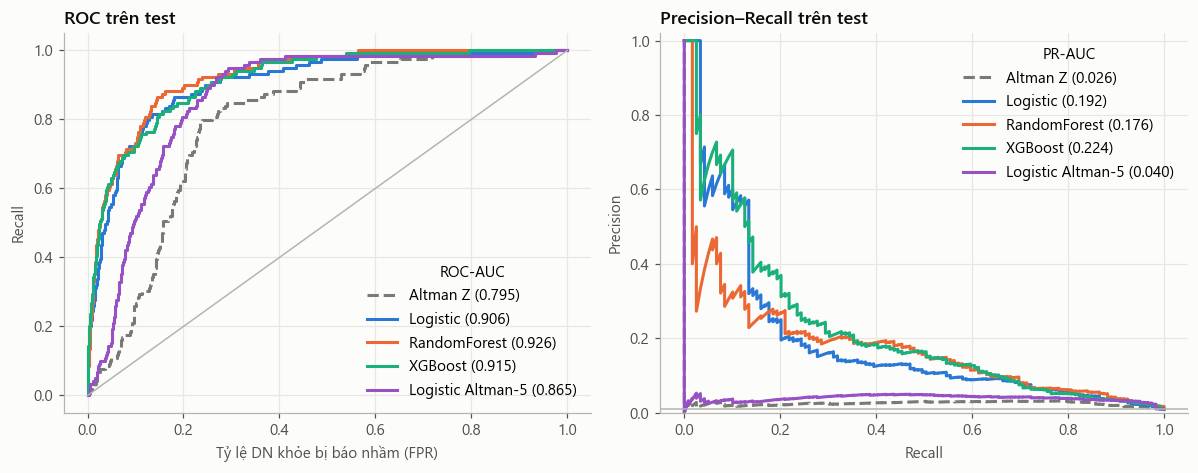

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
t = y['test']
for name in score:
    s = score[name]['test']
    style = {'color': C_MODEL[name], 'ls': '--' if name == 'Altman Z' else '-'}
    fpr, tpr, _ = roc_curve(t, s)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(t, s):.3f})", **style)
    pr, rc, _ = precision_recall_curve(t, s)
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(t, s):.3f})", **style)
ax[0].plot([0, 1], [0, 1], color='#b5b4ae', lw=1)
ax[1].axhline(t.mean(), color='#b5b4ae', lw=1)
ax[1].set_ylim(0, 1.02)
ax[0].set(title='ROC trên test', xlabel='Tỷ lệ DN khỏe bị báo nhầm (FPR)', ylabel='Recall')
ax[1].set(title='Precision–Recall trên test', xlabel='Recall', ylabel='Precision')
ax[0].legend(title='ROC-AUC', loc='lower right'); ax[1].legend(title='PR-AUC', loc='upper right')
plt.tight_layout(); plt.show()

**Tập phát triển 2015–2018.** So sánh thứ hạng bằng Average Precision và ROC-AUC. Bootstrap theo công ty ở mục kế tiếp đo bất định của các chênh lệch trên mẫu này. Quyết định champion dùng các cặp kết quả theo năm ở mục 7.

### Chênh lệch giữa các mô hình có đáng tin không?

Test chỉ có khoảng 119 sự kiện, nên cần khoảng tin cậy. Bootstrap được lấy theo **công ty** vì các năm của một công ty không độc lập.

In [20]:
test_firms = df.loc[masks['test'], 'company_name'].values
groups = pd.Series(np.arange(len(test_firms))).groupby(test_firms).apply(lambda s: s.values)
rng = np.random.default_rng(RANDOM_STATE)
t_arr = y['test'].values
boot = {name: [] for name in score}
for _ in range(500):
    idx = np.concatenate(groups.values[rng.integers(0, len(groups), len(groups))])
    if np.unique(t_arr[idx]).size < 2:
        continue
    for name in score:
        boot[name].append((roc_auc_score(t_arr[idx], score[name]['test'][idx]),
                           average_precision_score(t_arr[idx], score[name]['test'][idx])))
boot = {k: np.array(v) for k, v in boot.items()}

def ci(a): return f'{np.mean(a):.3f} [{np.percentile(a, 2.5):.3f}; {np.percentile(a, 97.5):.3f}]'
display(pd.DataFrame({n: {'ROC-AUC (Khoảng tin cậy 95%)': ci(b[:, 0]), 'PR-AUC (Khoảng tin cậy 95%)': ci(b[:, 1])} for n, b in boot.items()}).T)

others = [n for n in score if n != BEST]
display(pd.DataFrame({f'{BEST} − {o}': {'Chênh ROC-AUC (Khoảng tin cậy 95%)': ci(boot[BEST][:, 0] - boot[o][:, 0]),
                                        'Chênh PR-AUC (Khoảng tin cậy 95%)': ci(boot[BEST][:, 1] - boot[o][:, 1])} for o in others}).T)

bootstrap_rows = []
for name in others:
    delta = boot[name] - boot[BEST]
    for j, metric in enumerate(('ROC-AUC', 'PR-AUC')):
        metric_fn = roc_auc_score if j == 0 else average_precision_score
        bootstrap_rows.append({'comparison': f'{name} − {BEST}', 'metric': metric,
            'difference': metric_fn(t_arr, score[name]['test']) - metric_fn(t_arr, score[BEST]['test']),
            'lo95': np.quantile(delta[:, j], .025), 'hi95': np.quantile(delta[:, j], .975),
            'bootstrap_valid': len(delta)})
bootstrap_differences = pd.DataFrame(bootstrap_rows)
bootstrap_differences.to_csv(RESULTS / 'model_bootstrap_differences.csv', index=False)

,ROC-AUC (Khoảng tin cậy 95%),PR-AUC (Khoảng tin cậy 95%)
Altman Z,0.795 [0.764; 0.821],0.027 [0.021; 0.034]
Logistic,0.907 [0.879; 0.931],0.195 [0.136; 0.267]
RandomForest,0.925 [0.905; 0.943],0.181 [0.122; 0.255]
XGBoost,0.915 [0.894; 0.935],0.227 [0.155; 0.310]
Logistic Altman-5,0.864 [0.838; 0.889],0.041 [0.031; 0.052]


,Chênh ROC-AUC (Khoảng tin cậy 95%),Chênh PR-AUC (Khoảng tin cậy 95%)
Logistic − Altman Z,0.112 [0.080; 0.145],0.168 [0.109; 0.241]
Logistic − RandomForest,-0.019 [-0.033; -0.004],0.014 [-0.054; 0.076]
Logistic − XGBoost,-0.008 [-0.024; 0.005],-0.033 [-0.114; 0.044]
Logistic − Logistic Altman-5,0.043 [0.017; 0.070],0.154 [0.097; 0.223]


### Bất định của chênh lệch mô hình

Bootstrap 500 lần theo công ty, mang theo toàn bộ các năm của công ty và dùng cùng mẫu cho tất cả mô hình. Chênh lệch được tính ghép cặp. Khoảng chứa 0 nghĩa là chưa đủ bằng chứng về ưu thế theo chỉ số đang xét; không chứng minh hai mô hình tương đương.

Khoảng tin cậy phản ánh biến động thành phần công ty ở test với mô hình cố định, chưa bao gồm bất định từ huấn luyện, chọn siêu tham số và biến động vĩ mô chung. Xem bảng chênh lệch ngay phía trên, không suy ra ý nghĩa thống kê bằng cách so một điểm mới với khoảng tin cậy cũ.

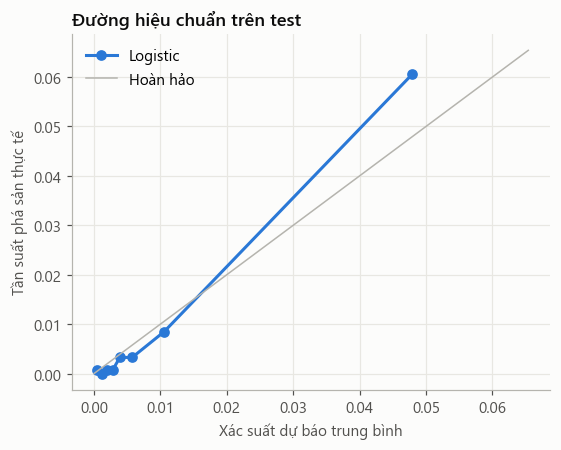

Tổng dự báo: 114.6 sự kiện | Thực tế: 119


,n,events,observed,predicted,expected_events,gap
decile,,,,,,
"(-0.000999377, 0.000684]",1229,1,0.0008,0.0003,0.3962,0.0005
"(0.000684, 0.00136]",1228,0,0.0000,0.0010,1.2754,-0.0010
"(0.00136, 0.00196]",1228,0,0.0000,0.0017,2.0304,-0.0017
"(0.00196, 0.00253]",1228,1,0.0008,0.0022,2.7597,-0.0014
"(0.00253, 0.00325]",1228,1,0.0008,0.0029,3.5252,-0.0021
"(0.00325, 0.00429]",1228,4,0.0033,0.0037,4.5925,-0.0005
"(0.00429, 0.00587]",1228,2,0.0016,0.0050,6.1516,-0.0034
"(0.00587, 0.0095]",1228,7,0.0057,0.0074,9.1373,-0.0017
"(0.0095, 0.0193]",1228,17,0.0138,0.0134,16.4004,0.0005


,n,events,observed,predicted,expected_events,gap
year,,,,,,
2015,3354,33,0.0098,0.0108,36.3404,-0.0010
2016,3191,29,0.0091,0.0088,28.1754,0.0003
2017,3014,21,0.0070,0.0082,24.8047,-0.0013
2018,2723,36,0.0132,0.0093,25.2393,0.0040


,year,n,events,observed,predicted,expected_events,gap,model,method
0,2015,3354,33,0.0098,0.0127,42.4615,-0.0028,Logistic,Platt OOF
1,2016,3191,29,0.0091,0.0104,33.1908,-0.0013,Logistic,Platt OOF
2,2017,3014,21,0.0070,0.0097,29.2314,-0.0027,Logistic,Platt OOF
3,2018,2723,36,0.0132,0.0109,29.6826,0.0023,Logistic,Platt OOF
0,2015,3354,33,0.0098,0.0108,36.3404,-0.0010,Logistic,Chỉnh hệ số chặn
1,2016,3191,29,0.0091,0.0088,28.1754,0.0003,Logistic,Chỉnh hệ số chặn
2,2017,3014,21,0.0070,0.0082,24.8047,-0.0013,Logistic,Chỉnh hệ số chặn
3,2018,2723,36,0.0132,0.0093,25.2393,0.0040,Logistic,Chỉnh hệ số chặn
0,2015,3354,33,0.0098,0.0162,54.4197,-0.0064,XGBoost,Platt OOF
1,2016,3191,29,0.0091,0.0140,44.6896,-0.0049,XGBoost,Platt OOF


,decile,n,events,observed,predicted,expected_events,gap,model,method
0,1,1229,1,0.0008,0.0004,0.4720,0.0004,Logistic,Platt OOF
1,2,1228,0,0.0000,0.0012,1.5192,-0.0012,Logistic,Platt OOF
2,3,1228,0,0.0000,0.0020,2.4182,-0.0020,Logistic,Platt OOF
3,4,1228,1,0.0008,0.0027,3.2864,-0.0019,Logistic,Platt OOF
4,5,1228,1,0.0008,0.0034,4.1975,-0.0026,Logistic,Platt OOF
5,6,1228,4,0.0033,0.0045,5.4673,-0.0012,Logistic,Platt OOF
6,7,1228,2,0.0016,0.0060,7.3216,-0.0043,Logistic,Platt OOF
7,8,1228,7,0.0057,0.0089,10.8699,-0.0032,Logistic,Platt OOF
8,9,1228,17,0.0138,0.0159,19.4868,-0.0020,Logistic,Platt OOF
9,10,1229,86,0.0700,0.0647,79.5275,0.0053,Logistic,Platt OOF


,model,method,expected,observed,brier,brier_reference,brier_skill
0,Logistic,Platt OOF,134.5664,119,0.0087,0.0096,0.0986
1,Logistic,Chỉnh hệ số chặn,114.5598,119,0.0087,0.0096,0.0965
2,XGBoost,Platt OOF,182.8176,119,0.0087,0.0096,0.0901
3,XGBoost,Chỉnh hệ số chặn,119.5218,119,0.0088,0.0096,0.0827


In [21]:
# Hiệu chuẩn: với xác suất dự báo p, tần suất thực tế có xấp xỉ p không?
fig, ax = plt.subplots(figsize=(5.2, 4.2))
frac, mean_p = calibration_curve(y['test'], pd_hat[BEST]['test'], n_bins=8, strategy='quantile')
ax.plot(mean_p, frac, marker='o', markersize=6, color=C_MODEL[BEST], label=BEST)
lim = max(mean_p.max(), frac.max()) * 1.08
ax.plot([0, lim], [0, lim], color='#b5b4ae', lw=1, label='Hoàn hảo')
ax.set(title='Đường hiệu chuẩn trên test', xlabel='Xác suất dự báo trung bình', ylabel='Tần suất phá sản thực tế')
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()
print('Tổng dự báo:', round(pd_hat[BEST]['test'].sum(), 1), 'sự kiện | Thực tế:', int(y['test'].sum()))

cal_decile, cal_year = calibration_tables(y['test'], pd_hat[BEST]['test'], df.loc[masks['test'], 'year'])
display(cal_decile.round(4)); display(cal_year.round(4))
cal_decile.to_csv(RESULTS / 'calibration_deciles.csv')
cal_year.to_csv(RESULTS / 'calibration_years.csv')

years_test = df.loc[masks['test'], 'year']
by_year, by_decile, skills = [], [], []
for model_name in dict.fromkeys([BEST, 'XGBoost']):
    for method, probs in [('Platt OOF', pd_oof), ('Chỉnh hệ số chặn', pd_hat)]:
        p = probs[model_name]['test']
        dec, yr = calibration_tables(y['test'], p, years_test)
        # Giữ đúng cùng nhóm doanh nghiệp trước/sau chỉnh chặn (biến đổi đơn điệu).
        dec.index = np.arange(1, len(dec) + 1)
        by_decile.append(dec.rename_axis('decile').reset_index().assign(model=model_name, method=method))
        by_year.append(yr.reset_index().assign(model=model_name, method=method))
        bs = brier_score_loss(y['test'], p)
        bs_ref = np.mean((y['test'] - recent_rate)**2)
        skills.append(dict(model=model_name, method=method, expected=p.sum(), observed=y['test'].sum(),
                           brier=bs, brier_reference=bs_ref, brier_skill=1-bs/bs_ref))
for title, table in [('calibration_methods_years', pd.concat(by_year)), ('calibration_methods_deciles', pd.concat(by_decile)),
                     ('calibration_skill', pd.DataFrame(skills))]:
    display(table.round(4))
    table.to_csv(RESULTS / f'{title}.csv', index=False)

**Giới hạn diễn giải.** PR-AUC cần so với mức tham chiếu bằng tỷ lệ phá sản, không gán nhãn “tốt” chỉ từ một con số. Với dữ liệu hiếm sự kiện, khoảng tin cậy có thể rộng. Xem số sự kiện, tỷ lệ nền và chênh lệch ghép cặp cùng nhau.

Brier, tổng sự kiện dự báo và độ lệch theo từng năm đánh giá xác suất sau hiệu chuẩn. Một đường hiệu chuẩn tổng thể gần đường chéo có thể che khuất sai lệch ở năm cụ thể. Kết quả test này là đánh giá hồi cứu, không xác nhận mô hình đã sẵn sàng triển khai.

**Kiểm tra lệch mức của XGBoost.** Trên cùng 119 ca quan sát, hiệu chuẩn OOF cho tổng 182,8 ca kỳ vọng. Chỉ đổi hệ số chặn cho 119,5 ca. Ở bảy nhóm có điểm thấp nhất, số ca kỳ vọng chuyển từ 30,4 xuống 19,4, so với 9 ca thực tế. Các nhóm ít hoặc bằng 0 ca cần đọc bằng số đếm thay vì tỷ số.

Brier skill = 1 − Brier mô hình / Brier của dự báo hằng số bằng tỷ lệ sự kiện valid. Với XGBoost, chỉ số chuyển từ 9,0% sang 8,3%. Mức 0 tương ứng với cách dự báo hằng số. Thay đổi hệ số chặn giữ nguyên thứ hạng. Tần suất nền khác nhau giữa các giai đoạn và độ dài lịch sử fit ngắn hơn của các mô hình OOF là hai giả thuyết cho sai lệch ban đầu.

## 8. Chọn ngưỡng cho hành động rà soát

**Cảnh báo nghĩa là rà soát hồ sơ**, không tự động từ chối tín dụng. Mỗi hồ sơ được rà soát tốn chi phí C, kể cả cảnh báo đúng. Đặt L = LGD × EAD là tổn thất khi vỡ nợ; e là tỷ lệ tổn thất có thể tránh được nhờ rà soát và hành động tiếp theo.

- Không cảnh báo: tổn thất kỳ vọng = PD × L.
- Cảnh báo: chi phí kỳ vọng = C + PD × (1−e) × L.
- Cảnh báo có lợi khi PD × e × LGD × EAD > C, tức ngưỡng lý thuyết **C / (e × LGD × EAD)**.
- Trên mẫu có nhãn: **tổng chi phí = C × (TP+FP) + L × FN + (1−e) × L × TP**.

Notebook minh họa C = 1 triệu VND, EAD = 1 tỷ VND, LGD = 45%, e = 2%, 5%, 10%, 20%; kịch bản chính e = 10%. Đây là giả định quy đổi cho mỗi hồ sơ, không phải số liệu khoản vay có trong dataset hay chuẩn Basel được áp dụng. Ngưỡng thực nghiệm tối thiểu hóa chi phí trên valid; khóa trước khi chấm test. “Tổn thất tránh được” là kết quả kịch bản, chưa phải tác động can thiệp được kiểm chứng. Khi EAD/LGD/chi phí khác nhau giữa hồ sơ, cần quyết định theo từng hồ sơ thay vì ngưỡng PD chung.

In [22]:
p_val, p_te = pd_hat[BEST]['valid'], pd_hat[BEST]['test']
t_val, t_te = y['valid'].values, y['test'].values
REVIEW_COST, EAD, LGD = 1_000_000., 1_000_000_000., .45
EFFECTIVENESS, MAIN_EFFECT = (.02, .05, .10, .20), .10

def confusion(t, p, thr):
    pred = np.asarray(p) >= thr
    t = np.asarray(t)
    return (int((pred & (t == 1)).sum()), int((pred & (t == 0)).sum()),
            int((~pred & (t == 1)).sum()), int((~pred & (t == 0)).sum()))

policies, cost_curves, rows = {}, {}, []
for effect in EFFECTIVENESS:
    th, curve = review_policy(t_val, p_val, REVIEW_COST, EAD, LGD, effect)
    policies[effect], cost_curves[effect] = th, curve
    tp, fp, fn, tn = confusion(t_te, p_te, th)
    cost = REVIEW_COST*(tp+fp) + EAD*LGD*fn + (1-effect)*EAD*LGD*tp
    no_review = EAD*LGD*(tp+fn)
    rows.append({'Hiệu quả giả định': effect, 'Ngưỡng': th,
                 'Ngưỡng lý thuyết': REVIEW_COST/(effect*LGD*EAD),
                 'Recall': tp/max(tp+fn,1), 'Precision': tp/max(tp+fp,1),
                 'FPR': fp/max(fp+tn,1), '% dòng bị cảnh báo': (tp+fp)/len(t_te),
                 'TP':tp,'FP':fp,'FN':fn,'TN':tn,
                 'Chi phí / không rà soát':cost/no_review,
                 'Lợi ích ròng giả định (VND)':no_review-cost})
policy_table = pd.DataFrame(rows).set_index('Hiệu quả giả định')
display(policy_table.style.format({c:'{:.2%}' for c in ['Ngưỡng','Ngưỡng lý thuyết','Recall','Precision','FPR','% dòng bị cảnh báo']}
    | {'Chi phí / không rà soát':'{:.4f}', 'Lợi ích ròng giả định (VND)':'{:,.0f}'}))
THRESHOLD = policies[MAIN_EFFECT]
grid = cost_curves[MAIN_EFFECT]['threshold'].to_numpy()
print(f'Ngưỡng rà soát chính: {THRESHOLD:.2%}; hiệu quả giả định: {MAIN_EFFECT:.0%}')
policy_table.to_csv(RESULTS / 'review_policies.csv')

# Hòa vốn cho một danh sách cố định: lợi ích ròng = e × L × TP − C × số rà soát.
def policy_economics(label, chosen, effect):
    n_review = int(chosen.sum())
    tp = int(t_te[chosen].sum())
    gross_avoidable = EAD * LGD * tp
    return {'policy': label, 'e': effect, 'reviewed': n_review, 'TP': tp, 'FP': n_review-tp,
            'recall': tp/t_te.sum(), 'precision': tp/n_review if n_review else np.nan,
            'minimum_e': REVIEW_COST*n_review/gross_avoidable if tp else np.nan,
            'maximum_review_cost': effect*gross_avoidable/n_review if n_review else np.nan,
            'net_benefit': effect*gross_avoidable-REVIEW_COST*n_review}
economic_rows = [policy_economics(f'Ngưỡng valid e={e:.0%}', p_te >= th, e) for e, th in policies.items()]
years = df.loc[masks['test'], 'year'].to_numpy()
for fraction in (.05, .10):
    chosen = np.zeros(len(t_te), dtype=bool)
    for year in np.unique(years):
        idx = np.flatnonzero(years == year)
        order = np.argsort(-p_te[idx], kind='stable')
        chosen[idx[order[:int(len(idx)*fraction)]]] = True
    economic_rows.append(policy_economics(f'Top {fraction:.0%} mỗi năm', chosen, MAIN_EFFECT))
economic_table = pd.DataFrame(economic_rows)
display(economic_table.round(4))
economic_table.to_csv(RESULTS / 'economic_breakeven.csv', index=False)

,Ngưỡng,Ngưỡng lý thuyết,Recall,Precision,FPR,% dòng bị cảnh báo,TP,FP,FN,TN,Chi phí / không rà soát,Lợi ích ròng giả định (VND)
Hiệu quả giả định,,,,,,,,,,,,
0.020000,19.66%,11.11%,13.45%,45.71%,0.16%,0.28%,16,19,103,12144,0.9980,"109,000,000"
0.050000,2.62%,4.44%,65.55%,9.21%,6.32%,6.90%,78,769,41,11394,0.9830,"908,000,000"
0.100000,1.37%,2.22%,81.51%,5.57%,13.52%,14.18%,97,1645,22,10518,0.9510,"2,623,000,000"
0.200000,1.08%,1.11%,84.03%,4.58%,17.13%,17.78%,100,2084,19,10079,0.8727,"6,816,000,000"


Ngưỡng rà soát chính: 1.37%; hiệu quả giả định: 10%


,policy,e,reviewed,TP,FP,recall,precision,minimum_e,maximum_review_cost,net_benefit
0,Ngưỡng valid e=2%,0.02,35,16,19,0.1345,0.4571,0.0049,4.114286e+06,1.090000e+08
1,Ngưỡng valid e=5%,0.05,847,78,769,0.6555,0.0921,0.0241,2.072019e+06,9.080000e+08
2,Ngưỡng valid e=10%,0.10,1742,97,1645,0.8151,0.0557,0.0399,2.505741e+06,2.623000e+09
3,Ngưỡng valid e=20%,0.20,2184,100,2084,0.8403,0.0458,0.0485,4.120879e+06,6.816000e+09
4,Top 5% mỗi năm,0.10,612,63,549,0.5294,0.1029,0.0216,4.632353e+06,2.223000e+09
5,Top 10% mỗi năm,0.10,1227,87,1140,0.7311,0.0709,0.0313,3.190709e+06,2.688000e+09


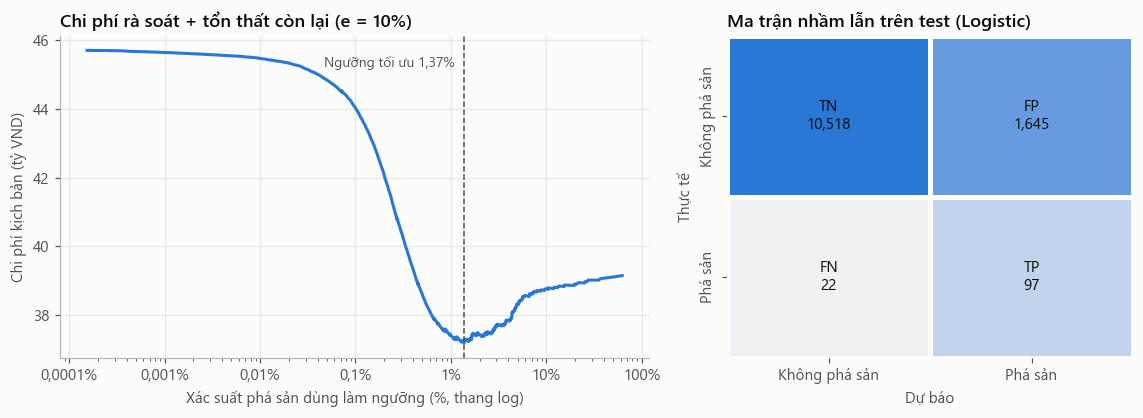

In [23]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw={'width_ratios': [1.45, 1]})
curve = cost_curves[MAIN_EFFECT]['cost'].to_numpy() / 1e9
ax[0].plot(grid, curve, color=C_MODEL[BEST])
ax[0].axvline(THRESHOLD, color='#52514e', ls='--', lw=1)
threshold_pct = f'{THRESHOLD:.2%}'.replace('.', ',')
ax[0].annotate(f'Ngưỡng tối ưu {threshold_pct}', (THRESHOLD, curve.max()), xytext=(-6, -4),
               textcoords='offset points', ha='right', va='top', color='#52514e', fontsize=9)
ax[0].set_xscale('log')
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda p, _: f'{100 * p:g}%'.replace('.', ',')))
ax[0].set(title=f'Chi phí rà soát + tổn thất còn lại (e = {MAIN_EFFECT:.0%})',
          xlabel='Xác suất phá sản dùng làm ngưỡng (%, thang log)', ylabel='Chi phí kịch bản (tỷ VND)')

tp, fp, fn, tn = confusion(t_te, p_te, THRESHOLD)
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(np.log1p(cm), annot=np.array([[f'TN\n{tn:,}', f'FP\n{fp:,}'], [f'FN\n{fn:,}', f'TP\n{tp:,}']]), fmt='',
            cmap=sns.light_palette('#2a78d6', as_cmap=True), cbar=False, linewidths=2, linecolor='#fcfcfb',
            xticklabels=['Không phá sản', 'Phá sản'], yticklabels=['Không phá sản', 'Phá sản'], ax=ax[1],
            annot_kws={'color': '#0b0b0b'})
ax[1].set(title=f'Ma trận nhầm lẫn trên test ({BEST})', xlabel='Dự báo', ylabel='Thực tế'); ax[1].grid(False)
plt.tight_layout(); plt.show()

**Diễn giải.** Tăng hiệu quả can thiệp e hoặc EAD/LGD làm tổn thất tránh được trên mỗi ca tăng, nên ngưỡng lý thuyết giảm. Tăng chi phí rà soát làm ngưỡng tăng. Ngưỡng thực nghiệm có thể giữ nguyên qua nhiều kịch bản vì các ngưỡng tạo cùng tập cảnh báo.

Đánh giá Recall/Precision theo ma trận test trong bảng. Chi phí rà soát phát sinh cho cả TP và FP. Lợi ích ròng âm nghĩa là chính sách kém hơn không rà soát dưới chính các giả định đó; không diễn giải là lợi nhuận thực tế. Tỷ lệ chi phí FN:FP cũ đã được thay bằng mô hình hành động này.

Với danh sách cố định N hồ sơ và TP ca đúng, hòa vốn khi e = C × N / (LGD × EAD × TP), hoặc khi C = e × LGD × EAD × TP / N. Bảng dùng nhãn đã biết để đánh giá hồi cứu. Phương án ngân sách xếp theo điểm trong từng năm trước khi xem nhãn, làm tròn số suất xuống và giữ thứ tự dòng khi bằng điểm.

Với danh sách chính gồm 1742 hồ sơ và 97 ca dương, hiệu quả tối thiểu là 3,99% ở chi phí 1 triệu đồng/hồ sơ. Nếu e = 10%, chi phí tối đa là 2,51 triệu đồng/hồ sơ.

## 9. Giải thích mô hình bằng SHAP

SHAP được tính cho XGBoost bằng `TreeExplainer`. Đơn vị là **log-odds trước hiệu chuẩn**, nên giá trị dùng để so sánh mức đóng góp, không phải cộng trực tiếp ra xác suất phá sản.

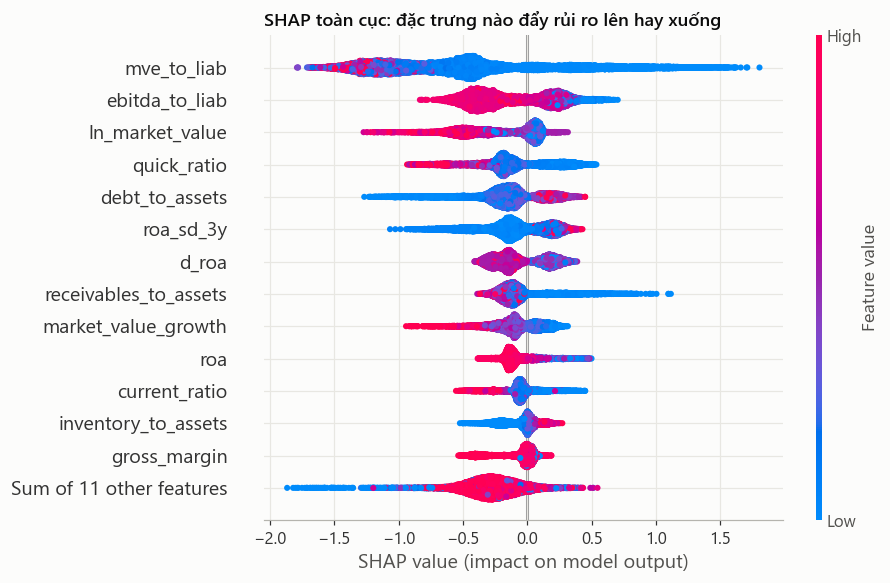

,|SHAP| trung bình,Tác động khi đặc trưng tăng,Kỳ vọng lý thuyết
mve_to_liab,0.719,−,−
ebitda_to_liab,0.297,−,−
ln_market_value,0.269,−,−
quick_ratio,0.246,−,−
debt_to_assets,0.227,+,+
roa_sd_3y,0.208,+,+
d_roa,0.187,−,−
receivables_to_assets,0.165,−,không rõ
market_value_growth,0.154,−,−
roa,0.130,−,−


In [24]:
explainer = shap.TreeExplainer(models['XGBoost'])
sv = explainer(X['test'])

plt.figure()
shap.plots.beeswarm(sv, max_display=14, show=False, plot_size=(8.5, 5.4))
plt.title('SHAP toàn cục: đặc trưng nào đẩy rủi ro lên hay xuống'); plt.tight_layout(); plt.show()

EXPECTED = {'current_ratio': '−', 'quick_ratio': '−', 'wc_to_assets': '−', 'debt_to_assets': '+', 'ltd_to_assets': '+',
            'mve_to_liab': '−', 'neg_equity': '+', 'roa': '−', 'ebit_to_assets': '−', 're_to_assets': '−', 'net_margin': '−',
            'gross_margin': '−', 'loss_2y': '+', 'ebitda_to_liab': '−', 'd_roa': '−', 'sales_growth': '−',
            'market_value_growth': '−', 'ln_market_value': '−', 'ln_assets': '−', 'roa_sd_3y': '+'}
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
top10 = mean_abs.index[:10]
sign = {f: np.corrcoef(X['test'][f], sv.values[:, FEATURES.index(f)])[0, 1] for f in top10}
top = pd.DataFrame({'|SHAP| trung bình': mean_abs.head(10).round(3),
                    'Tác động khi đặc trưng tăng': ['+' if sign[f] > 0 else '−' for f in top10],
                    'Kỳ vọng lý thuyết': [EXPECTED.get(f, 'không rõ') for f in top10]})
display(top)

### Giải thích hai ca dương có điểm XGBoost cao nhất và thấp nhất

CA DƯƠNG CÓ ĐIỂM CAO NHẤT: C_8385, FY2018 — xác suất phá sản ước tính 18.53%


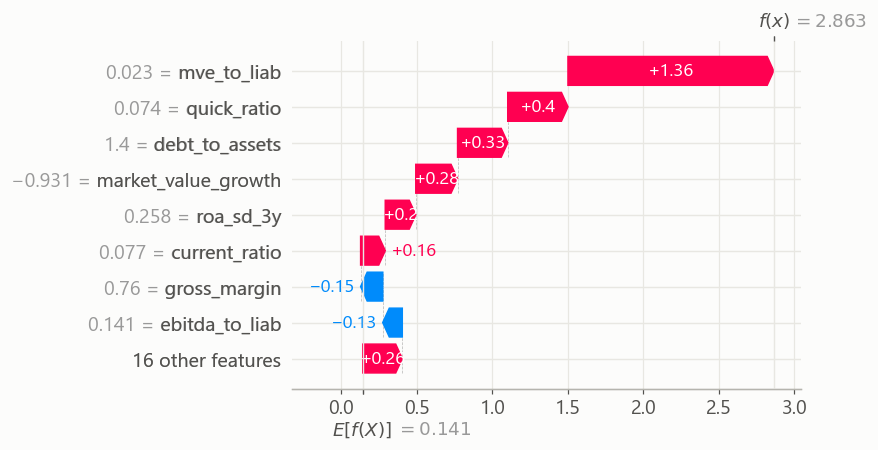

CA DƯƠNG CÓ ĐIỂM THẤP NHẤT: C_8688, FY2016 — xác suất phá sản ước tính 0.13%


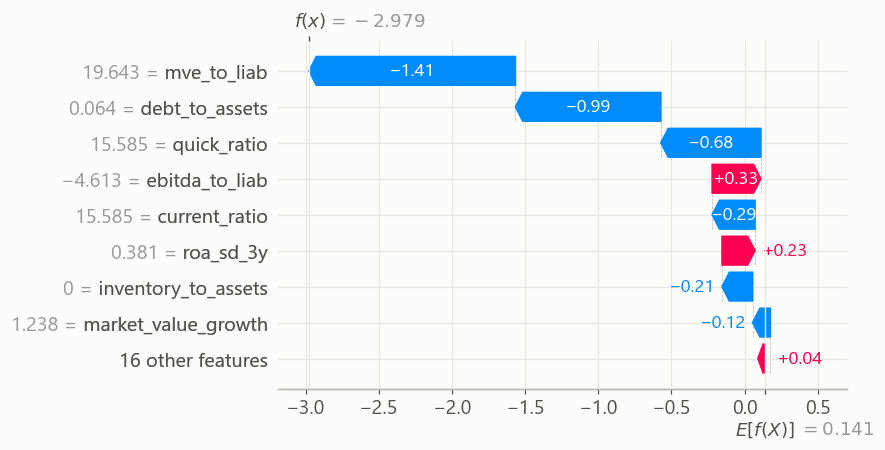

In [25]:
p_xgb = pd_hat['XGBoost']['test']
pos = np.where(t_te == 1)[0]
i_tp, i_fn = int(pos[np.argmax(p_xgb[pos])]), int(pos[np.argmin(p_xgb[pos])])
meta = df.loc[masks['test'], ['company_name', 'year']].reset_index(drop=True)

for i, label in [(i_tp, 'ca dương có điểm cao nhất'), (i_fn, 'ca dương có điểm thấp nhất')]:
    print(f"{label.upper()}: {meta.company_name[i]}, FY{meta.year[i]} — xác suất phá sản ước tính {p_xgb[i]:.2%}")
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=9, show=False)
    plt.gcf().set_size_inches(8, 4.2); plt.tight_layout(); plt.show()

**Giới hạn giải thích.** SHAP mô tả đóng góp vào điểm của mô hình XGBoost, không phải tác động nhân quả của tỷ số tài chính. Đặc trưng tương quan có thể chia sẻ đóng góp; dấu tương quan giữa một biến và SHAP không chứng minh quan hệ đơn điệu.

Hai hồ sơ phía trên được chọn theo điểm cao nhất/thấp nhất trong các ca dương, không phải hai quan sát đại diện cho toàn bộ mẫu. Phần kiểm tra bổ sung trình bày Logistic gọn có VIF và XGBoost với ràng buộc đơn điệu định trước.

## 10. Danh sách cảnh báo FY2018 và đối chiếu thực tế

Đây là chấm điểm hồi cứu các doanh nghiệp FY2018 thuộc tập test với mô hình train đến 2011, không phải dự báo trực tiếp cho doanh nghiệp hiện tại. Dùng ngưỡng rà soát đã khóa từ valid. Nhãn thực tế trong bảng cũng tuân theo quy ước suy ra sự kiện của dataset.

In [26]:
final_model, final_cal = models[BEST], calibrators[BEST]

def score_firms(panel):
    # Nhận panel gốc (cột X1–X18, company_name, year; nên có các năm trước) và trả về xác suất phá sản năm t+1
    panel = panel.rename(columns=VAR_MAP)
    features = cleaner.transform(build_features(panel)[FEATURES])
    out = panel.loc[features.index, ['company_name', 'year']].copy()
    out['pd_next_year'] = final_cal.predict(to_logit(final_model.predict_proba(features)[:, 1]))
    return out

base_rate = float(y['train'].mean())
def band(p):
    return 'Cao' if p >= THRESHOLD else ('Theo dõi' if p >= base_rate else 'Thấp')

is_2018 = (meta.year == 2018).values
latest = meta[is_2018].copy()
latest['pd_next_year'] = p_te[is_2018]
latest['risk_band'] = latest['pd_next_year'].map(band)
latest['status_label'] = df.loc[masks['test'], 'status_label'].values[is_2018]

if BEST == 'XGBoost':
    best_sv = sv
elif BEST == 'RandomForest':
    best_sv = shap.TreeExplainer(models[BEST])(X['test'])[:, :, 1]
else:
    scale = models[BEST].named_steps['scale']
    best_sv = shap.LinearExplainer(models[BEST].named_steps['clf'], scale.transform(X['train']))(scale.transform(X['test']))
shap_2018 = best_sv.values[is_2018]
latest['top_reasons'] = [', '.join(FEATURES[j] for j in np.argsort(-row)[:3] if row[j] > 0) for row in shap_2018]
latest = latest.sort_values('pd_next_year', ascending=False)

tab = latest.groupby('risk_band').agg(so_dn=('company_name', 'size'), pd_tb=('pd_next_year', 'mean'),
                                      so_failed=('status_label', lambda s: (s == 'failed').sum())).reindex(['Cao', 'Theo dõi', 'Thấp'])
display(tab.style.format({'pd_tb': '{:.2%}'}))
display(latest.head(20).style.format({'pd_next_year': '{:.1%}'}).hide(axis='index'))

latest.to_csv('du_bao_pha_san_FY2018.csv', index=False, encoding='utf-8-sig')
print('Đã lưu du_bao_pha_san_FY2018.csv với', len(latest), 'doanh nghiệp')

,so_dn,pd_tb,so_failed
risk_band,,,
Cao,396,4.19%,30
Theo dõi,321,1.00%,1
Thấp,2006,0.27%,5


company_name,year,pd_next_year,risk_band,status_label,top_reasons
C_2585,2018,66.0%,Cao,failed,"ln_market_value, ln_assets, neg_equity"
C_8385,2018,38.9%,Cao,failed,"ln_market_value, ln_assets, quick_ratio"
C_7938,2018,26.5%,Cao,failed,"ln_assets, quick_ratio, neg_equity"
C_6274,2018,21.3%,Cao,alive,"ln_market_value, ln_assets, quick_ratio"
C_6626,2018,21.1%,Cao,failed,"ln_market_value, quick_ratio, neg_equity"
C_5219,2018,20.3%,Cao,alive,"ln_market_value, ebitda_to_liab, ebit_to_assets"
C_2857,2018,20.1%,Cao,alive,"ln_market_value, ln_assets, neg_equity"
C_8239,2018,19.0%,Cao,alive,"ln_market_value, gross_margin, loss_2y"
C_7816,2018,18.2%,Cao,alive,"ln_market_value, quick_ratio, neg_equity"
C_8369,2018,16.9%,Cao,alive,"ln_market_value, ln_assets, neg_equity"


Đã lưu du_bao_pha_san_FY2018.csv với 2723 doanh nghiệp


In [27]:
# Kiểm tra hàm score_firms: chấm lại toàn bộ lịch sử của công ty rủi ro nhất phải ra đúng kết quả ở trên
firm_name = latest.iloc[0]['company_name']
history = raw[raw['company_name'] == firm_name]
scored = score_firms(history)
assert np.isclose(scored.loc[scored.year == 2018, 'pd_next_year'].iloc[0], latest.iloc[0]['pd_next_year'], atol=1e-6)
scored.tail(5).style.format({'pd_next_year': '{:.2%}'}).hide(axis='index')

company_name,year,pd_next_year
C_2585,2014,1.37%
C_2585,2015,0.85%
C_2585,2016,1.77%
C_2585,2017,5.16%
C_2585,2018,65.96%


**Đọc danh sách.** Bảng trên đối chiếu số hồ sơ, xác suất trung bình và số doanh nghiệp mang nhãn failed ở từng nhóm. Ngưỡng và xác suất có thể đổi khi phương pháp hiệu chuẩn thay đổi; số liệu được tính lại thay vì giữ nhận xét của lần chạy cũ. CSV `du_bao_pha_san_FY2018.csv` là đầu ra hồi cứu, không phải khuyến nghị mua/bán hay quyết định cấp tín dụng.

## 11. Độ nhạy với cập nhật mô hình và nhãn gốc

Đối chiếu mô hình train đến 2011 với mô hình refit đến 2014 trên cùng test. Refit cả bước làm sạch trên đúng tập huấn luyện mới, giữ tham số đã chọn và không chọn lại bằng test. Bootstrap ghép cặp theo công ty cho chênh lệch refit − gốc.

Nhánh `status_label` là kiểm tra một câu hỏi khác: công ty có nhãn failed trong toàn bộ lịch sử hay không. Không diễn giải điểm của nhánh này là chất lượng dự báo phá sản năm kế tiếp.

In [28]:
robust_rows, refit_predictions, refit_ci_rows = [], {}, []
for name, model in models.items():
    refit_mask = masks['train'] | masks['valid']
    _, _, p_refit = fit_partition(model, features_raw[FEATURES], df['target'], refit_mask, masks['test'])
    refit_predictions[name] = p_refit
    for label, target, predictions in [('Gốc · train đến 2011', y['test'], raw_prob[name]['test']),
                                        ('Refit · train đến 2014', y['test'], p_refit)]:
        robust_rows.append({'model':name,'scenario':label,**ranking_metrics(target,predictions)})
    _, _, p_original = fit_partition(model, features_raw[FEATURES], df['failed_firm'], masks['train'], masks['test'])
    robust_rows.append({'model':name,'scenario':'status_label gốc',
                       **ranking_metrics(df.loc[masks['test'],'failed_firm'],p_original)})
    ci_refit = paired_bootstrap(y['test'], {'gốc':raw_prob[name]['test'],'refit':p_refit},
                               test_firms, 'gốc', seed=RANDOM_STATE)
    refit_ci_rows.append(ci_refit.assign(model=name))
robust = pd.DataFrame(robust_rows)
refit_ci = pd.concat(refit_ci_rows,ignore_index=True)
display(robust.round(4)); display(refit_ci.round(4))
robust.to_csv(RESULTS / 'refit_and_original_label.csv',index=False)
refit_ci.to_csv(RESULTS / 'refit_paired_bootstrap.csv',index=False)

,model,scenario,n,events,prevalence,ROC-AUC,PR-AUC
0,Logistic,Gốc · train đến 2011,12282,119,0.0097,0.9064,0.1919
1,Logistic,Refit · train đến 2014,12282,119,0.0097,0.9078,0.2030
2,Logistic,status_label gốc,12282,287,0.0234,0.8133,0.1188
3,RandomForest,Gốc · train đến 2011,12282,119,0.0097,0.9255,0.1764
4,RandomForest,Refit · train đến 2014,12282,119,0.0097,0.9273,0.2032
5,RandomForest,status_label gốc,12282,287,0.0234,0.8655,0.2053
6,XGBoost,Gốc · train đến 2011,12282,119,0.0097,0.9153,0.2235
7,XGBoost,Refit · train đến 2014,12282,119,0.0097,0.9219,0.2424
8,XGBoost,status_label gốc,12282,287,0.0234,0.8642,0.2353


,comparison,metric,difference,lo95,hi95,bootstrap_valid,model
0,refit − gốc,ROC-AUC,0.0014,-0.0010,0.0039,500,Logistic
1,refit − gốc,PR-AUC,0.0111,0.0040,0.0206,500,Logistic
2,refit − gốc,ROC-AUC,0.0018,-0.0024,0.0065,500,RandomForest
3,refit − gốc,PR-AUC,0.0268,0.0073,0.0509,500,RandomForest
4,refit − gốc,ROC-AUC,0.0066,0.0001,0.0129,500,XGBoost
5,refit − gốc,PR-AUC,0.0188,-0.0130,0.0481,500,XGBoost


**Diễn giải refit.** Chỉ xem chênh lệch là có bằng chứng theo phép bootstrap này khi khoảng tin cậy ghép cặp không chứa 0. Nếu chứa 0, mức tăng quan sát được chưa đủ để kết luận cập nhật cải thiện mô hình. Khoảng của phép kiểm tra này không bao gồm việc huấn luyện lại trên nhiều mẫu train, nên vẫn chưa mô tả toàn bộ bất định triển khai.

## 12. Quy tắc chọn mô hình và giới hạn

Quy tắc cho lần phân tích này dùng Logistic đầy đủ làm champion mặc định. XGBoost gốc chỉ thay thế nếu PR-AUC trung bình theo năm cao hơn và kiểm định dấu hai phía trên các chênh lệch PR-AUC từng năm có p < 0,05. Mỗi năm có trọng số bằng nhau. RF và XGBoost đơn điệu là đối chứng thăm dò. Quy tắc được ghi rõ sau khi đã xem dữ liệu, nên cần xác nhận trên giai đoạn mới. Bảy năm là mẫu nhỏ và các năm có thể phụ thuộc nhau.

Các bảng chi phí, danh sách FY2018 và giám sát dùng champion đã chọn. SHAP ở mục 9 phân tích riêng XGBoost. Đánh giá trên 2015–2018 mô tả chất lượng phát triển; cần giai đoạn mới để xác nhận.

Ở lần chạy này Logistic là champion. XGBoost gốc là challenger để đánh giá lại khi có giai đoạn xác nhận mới.

## 13. Backtest theo năm và kịch bản khủng hoảng

Backtest 2012–2018 dùng expanding window theo **năm**, không chia ngẫu nhiên từng dòng. Với test năm Y: inner train ≤ Y−4, inner valid = Y−2; fit mô hình cuối đến Y−2, để hở Y−1 do nhãn t+1. Mỗi bước fit lại cleaner và trọng số lớp từ train. Lưới định trước gồm hai cấu hình mỗi mô hình; RF 100 cây để kiểm soát thời gian. Đây là bằng chứng chính dùng ở mục 7. Mỗi năm được chấm bằng mô hình đã chọn tham số từ quá khứ.

Stress test giữ train đến 2006, test lần lượt 2007–2010; chọn tham số bằng train ≤2003/valid 2005. Mốc stress này là thiết kế hồi cứu được yêu cầu; nhãn cuối train có thể rơi vào 2007, và không có ngày công bố để bảo đảm mô phỏng quyết định tại đầu năm 2007. Không coi đó là backtest giao dịch trực tiếp.

Báo cả số sự kiện/tỷ lệ nền; AUC và AP từng năm có ít ca vẫn bất định. Mục 7 yêu cầu xét cả chênh AP trung bình và tính nhất quán của chênh lệch theo năm. [Nguyên tắc chia theo thời gian](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

,year,model,train_end,candidate,n,events,prevalence,ROC-AUC,PR-AUC
0,2012,Logistic,2010,1,3485,26,0.0075,0.9539,0.2307
1,2012,RandomForest,2010,1,3485,26,0.0075,0.9544,0.2515
2,2012,XGBoost,2010,0,3485,26,0.0075,0.9556,0.2329
3,2012,XGBoost đơn điệu,2010,0,3485,26,0.0075,0.9542,0.2211
4,2013,Logistic,2011,0,3484,28,0.0080,0.8900,0.0987
5,2013,RandomForest,2011,1,3484,28,0.0080,0.8655,0.0944
6,2013,XGBoost,2011,1,3484,28,0.0080,0.8995,0.1040
7,2013,XGBoost đơn điệu,2011,1,3484,28,0.0080,0.8921,0.1073
8,2014,Logistic,2012,1,3504,33,0.0094,0.9232,0.0645
9,2014,RandomForest,2012,1,3504,33,0.0094,0.9020,0.1684


,year,model,train_end,n,events,prevalence,ROC-AUC,PR-AUC
0,2007,Logistic,2006,4009,59,0.0147,0.8734,0.1137
1,2008,Logistic,2006,3857,58,0.0150,0.9164,0.1785
2,2009,Logistic,2006,3743,23,0.0061,0.8384,0.0540
3,2010,Logistic,2006,3625,35,0.0097,0.8677,0.0494
4,2007,RandomForest,2006,4009,59,0.0147,0.8633,0.1317
5,2008,RandomForest,2006,3857,58,0.0150,0.8967,0.1432
6,2009,RandomForest,2006,3743,23,0.0061,0.8704,0.0620
7,2010,RandomForest,2006,3625,35,0.0097,0.8751,0.0710
8,2007,XGBoost,2006,4009,59,0.0147,0.8746,0.1344
9,2008,XGBoost,2006,3857,58,0.0150,0.8969,0.1165


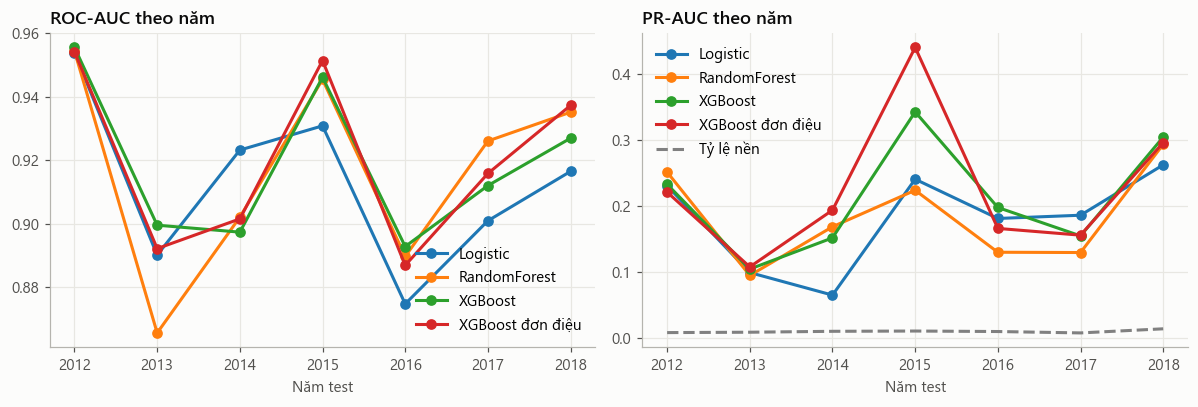

In [29]:
# Dùng lại kết quả backtest đã tính ở mục 7.
stress_results = stress_backtest(features_raw[FEATURES],df['target'],df['year'],RANDOM_STATE)
display(annual_backtest.round(4)); display(stress_results.round(4))
annual_backtest.to_csv(RESULTS / 'annual_backtest.csv',index=False)
inner_tuning.to_csv(RESULTS / 'backtest_inner_selection.csv',index=False)
stress_results.to_csv(RESULTS / 'stress_2007_2010.csv',index=False)
fig,axes = plt.subplots(1,2,figsize=(11,3.8))
for metric,ax in zip(['ROC-AUC','PR-AUC'],axes):
    for name,g in annual_backtest.groupby('model'):
        ax.plot(g.year,g[metric],marker='o',label=name)
    if metric == 'PR-AUC':
        base = annual_backtest.drop_duplicates('year')
        ax.plot(base.year,base.prevalence,ls='--',color='gray',label='Tỷ lệ nền')
    ax.set(title=metric+' theo năm',xlabel='Năm test'); ax.legend()
plt.tight_layout(); plt.show()

### 13.1. Độ nhạy của định nghĩa nhãn và kết cục chưa rõ

Nhãn hai năm = sự kiện suy ra `last_year+1` nằm trong t+1 hoặc t+2. Để không trộn ảnh hưởng của cửa sổ quan sát, cả nhánh t+1 và t+2 dùng train đến 2010, test 2015–2016. Chỉ giữ nhãn âm hai năm khi quan sát tiếp đến t+2 hoặc có căn cứ từ trạng thái cuối kỳ; bỏ các cửa sổ phải kiểm duyệt. Hai nhánh có mục tiêu khác nhau nên chênh AUC/AP không phải cải thiện trên cùng bài toán.

Nhánh loại công ty alive rời mẫu trước 2018 bỏ toàn bộ công ty đó khỏi train/test. Đây là kiểm tra hồi cứu phụ thuộc thông tin tương lai, có thể tạo thiên lệch sống sót; không phải quy tắc lọc áp dụng trực tiếp khi dự báo. Giữ tham số của mô hình chính để khảo sát độ nhạy, không tìm thêm trên test.

Không dùng các năm t > 2016 trong so sánh hai năm: dataset kết thúc năm 2018. Giữ riêng sự kiện dương ở đuôi nhưng không có thời gian theo dõi tương ứng cho nhóm âm sẽ làm lệch cơ cấu mẫu.

In [30]:
sensitivity_rows = []
two_year_target, matched_train, matched_test = two_year_sensitivity(df)
alive_early = df.failed_firm.eq(0) & df.last_year.lt(df.year.max())
assert df.loc[matched_test,'year'].max() <= df.year.max()-2
scenarios = [
    ('t+1 · cửa sổ chung',df.target,matched_train,matched_test),
    ('t+1/t+2 · cửa sổ chung',two_year_target,matched_train,matched_test),
    ('t+1 · bỏ alive rời sớm',df.target,masks['train'] & ~alive_early,masks['test'] & ~alive_early),
]
for label,target,tr_mask,te_mask in scenarios:
    for name,model in models.items():
        _,_,p = fit_partition(model,features_raw[FEATURES],target,tr_mask,te_mask)
        sensitivity_rows.append({'scenario':label,'model':name,**ranking_metrics(target[te_mask],p)})
label_sensitivity = pd.DataFrame(sensitivity_rows)
display(label_sensitivity.round(4))
label_sensitivity.to_csv(RESULTS / 'label_sensitivity.csv',index=False)
display(df.loc[matched_test, ['year']].assign(target_2y=two_year_target[matched_test]).groupby('year')['target_2y'].agg(['size','sum']))


,scenario,model,n,events,prevalence,ROC-AUC,PR-AUC
0,t+1 · cửa sổ chung,Logistic,5448,62,0.0114,0.9200,0.2867
1,t+1 · cửa sổ chung,RandomForest,5448,62,0.0114,0.9270,0.2614
2,t+1 · cửa sổ chung,XGBoost,5448,62,0.0114,0.9212,0.3138
3,t+1/t+2 · cửa sổ chung,Logistic,5448,109,0.0200,0.8944,0.2201
4,t+1/t+2 · cửa sổ chung,RandomForest,5448,109,0.0200,0.9146,0.2846
5,t+1/t+2 · cửa sổ chung,XGBoost,5448,109,0.0200,0.9031,0.3133
6,t+1 · bỏ alive rời sớm,Logistic,10531,119,0.0113,0.9188,0.2219
7,t+1 · bỏ alive rời sớm,RandomForest,10531,119,0.0113,0.9294,0.1948
8,t+1 · bỏ alive rời sớm,XGBoost,10531,119,0.0113,0.9199,0.2507


,size,sum
year,,
2015,2826,61
2016,2622,48


### 13.2. Cờ thiếu, Logistic gọn và ràng buộc đơn điệu

Cờ thiếu được tạo trước impute cho sáu biến lịch sử, gồm cả thiếu do chưa đủ lịch sử và đứt quãng. So sánh giữ nguyên tham số, không tìm lại theo test. Logistic gọn giữ đúng năm tỷ số Altman, gồm vốn hóa/nợ, rồi thêm EBITDA/nợ, log vốn hóa, tăng trưởng vốn hóa và độ biến động ROA; chỉ dùng train để loại dần biến VIF > 5. Nếu còn dưới tám biến, giữ kết quả lọc thay vì thêm biến để đủ số lượng.

XGBoost đơn điệu giả định rủi ro tăng theo nợ/tài sản và giảm theo thanh khoản, ROA, vốn hóa/nợ. Đây là ràng buộc có điều kiện khi giữ các biến khác cố định, không phải quan hệ nhân quả hay bảo đảm đúng cho mọi ngành. Bảng valid/test và bootstrap ghép cặp cho biết đánh đổi; các thử nghiệm này không tự động thay mô hình chính. [Tài liệu ràng buộc đơn điệu](https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html).

Trong backtest, XGBoost đơn điệu đạt AP cao hơn bản gốc ở 4/7 năm, chênh trung bình 0,013. Cả hai dùng cùng cửa sổ và hai cấu hình độ sâu ứng viên cho mỗi năm.

In [31]:
flag_features = features_raw[FEATURES].join(features_raw[LAG_FEATURES].isna().astype(float).add_suffix('_missing'))
variant_rows, variant_predictions = [], {}
for name,model in models.items():
    fitted,clean,p = fit_partition(model,flag_features,df.target,masks['train'],masks['test'])
    pv = fitted.predict_proba(clean.transform(flag_features.loc[masks['valid']]))[:,1]
    variant_predictions[name+' + cờ thiếu'] = (name,p)
    for split,pr in [('valid',pv),('test',p)]:
        variant_rows.append({'variant':name+' + cờ thiếu','split':split,**ranking_metrics(y[split],pr)})
        variant_rows.append({'variant':name+' gốc','split':split,**ranking_metrics(y[split],raw_prob[name][split])})
compact_features,vif,removed_vif = compact_columns(X['train'])
display(vif.to_frame().round(3))

if removed_vif.empty:
    print("Giữ nguyên cả 9 biến: không có biến nào có VIF > 5.")
else:
    print("Các biến bị loại do VIF cao:")
    display(removed_vif)
compact_model,compact_clean,pcompact = fit_partition(models['Logistic'],features_raw,df.target,masks['train'],masks['test'],compact_features)
display(pd.Series(compact_model.named_steps['clf'].coef_[0],index=compact_features,name='Hệ số chuẩn hóa (điều chuẩn)'))
vif.to_csv(RESULTS / 'compact_logistic_vif.csv')
constraints = MONOTONE
monotone = clone(models['XGBoost']).set_params(monotone_constraints=constraints,tree_method='hist')
mono_model,mono_clean,pmono = fit_partition(monotone,features_raw[FEATURES],df.target,masks['train'],masks['test'])
for label,model,clean,cols,pred,base in [
    ('Logistic gọn',compact_model,compact_clean,compact_features,pcompact,'Logistic'),
    ('XGBoost đơn điệu',mono_model,mono_clean,FEATURES,pmono,'XGBoost')]:
    variant_predictions[label] = (base,pred)
    pv = model.predict_proba(clean.transform(features_raw.loc[masks['valid'],cols]))[:,1]
    for split,pr in [('valid',pv),('test',pred)]:
        variant_rows.append({'variant':label,'split':split,**ranking_metrics(y[split],pr)})
variant_table = pd.DataFrame(variant_rows)
display(variant_table.round(4)); variant_table.to_csv(RESULTS / 'feature_variants.csv',index=False)
variant_ci = pd.concat([paired_bootstrap(y['test'],{base:raw_prob[base]['test'],label:p},test_firms,base,seed=RANDOM_STATE)
                        for label,(base,p) in variant_predictions.items()],ignore_index=True)
display(variant_ci.round(4)); variant_ci.to_csv(RESULTS / 'feature_variants_bootstrap.csv',index=False)

,VIF
wc_to_assets,2.695
re_to_assets,3.310
ebit_to_assets,3.703
mve_to_liab,1.211
asset_turnover,1.150
ebitda_to_liab,1.823
ln_market_value,1.267
market_value_growth,1.042
roa_sd_3y,1.608


Giữ nguyên cả 9 biến: không có biến nào có VIF > 5.


wc_to_assets          -0.399207
re_to_assets           0.118463
ebit_to_assets         0.179208
mve_to_liab           -1.285434
asset_turnover         0.103171
ebitda_to_liab        -0.621508
ln_market_value       -0.535363
market_value_growth   -0.405372
roa_sd_3y              0.057018
Name: Hệ số chuẩn hóa (điều chuẩn), dtype: float64

,variant,split,n,events,prevalence,ROC-AUC,PR-AUC
0,Logistic + cờ thiếu,valid,10473,87,0.0083,0.9131,0.0945
1,Logistic gốc,valid,10473,87,0.0083,0.9205,0.1010
2,Logistic + cờ thiếu,test,12282,119,0.0097,0.9001,0.1759
3,Logistic gốc,test,12282,119,0.0097,0.9064,0.1919
4,RandomForest + cờ thiếu,valid,10473,87,0.0083,0.9100,0.1402
5,RandomForest gốc,valid,10473,87,0.0083,0.9111,0.1540
6,RandomForest + cờ thiếu,test,12282,119,0.0097,0.9219,0.1802
7,RandomForest gốc,test,12282,119,0.0097,0.9255,0.1764
8,XGBoost + cờ thiếu,valid,10473,87,0.0083,0.9069,0.1548
9,XGBoost gốc,valid,10473,87,0.0083,0.9117,0.1728


,comparison,metric,difference,lo95,hi95,bootstrap_valid
0,Logistic + cờ thiếu − Logistic,ROC-AUC,-0.0064,-0.0166,0.0026,500
1,Logistic + cờ thiếu − Logistic,PR-AUC,-0.0160,-0.0360,-0.0015,500
2,RandomForest + cờ thiếu − RandomForest,ROC-AUC,-0.0036,-0.0092,0.0012,500
3,RandomForest + cờ thiếu − RandomForest,PR-AUC,0.0038,-0.0123,0.0240,500
4,XGBoost + cờ thiếu − XGBoost,ROC-AUC,-0.0043,-0.0112,0.0026,500
5,XGBoost + cờ thiếu − XGBoost,PR-AUC,-0.0088,-0.0326,0.0144,500
6,Logistic gọn − Logistic,ROC-AUC,-0.0649,-0.0986,-0.0362,500
7,Logistic gọn − Logistic,PR-AUC,-0.1560,-0.2271,-0.1017,500
8,XGBoost đơn điệu − XGBoost,ROC-AUC,0.0041,-0.0021,0.0105,500
9,XGBoost đơn điệu − XGBoost,PR-AUC,0.0191,-0.0204,0.0623,500


## 14. Giám sát phân phối và thứ tự rủi ro

PSI cho điểm và CSI cho các đặc trưng chính dùng biên phân vị cố định học trên train, có nhóm thiếu riêng và làm trơn 0,5 quan sát mỗi nhóm. Không dùng ngưỡng PSI phổ quát như một kiểm định thống kê. Dịch chuyển có thể đến từ quy mô, thành phần doanh nghiệp hoặc chu kỳ kinh tế, không tự chứng minh chất lượng mô hình giảm.

Bảng thứ tự rủi ro dùng cùng biên điểm train cho valid/test; vì vậy mỗi nhóm ở test không nhất thiết có 10% hồ sơ. Đọc tỷ lệ sự kiện theo nhóm cùng số dòng và số ca. Điểm train là in-sample, nên đây là mốc vận hành để theo dõi phân phối, không phải ước lượng hiệu quả ngoài mẫu.

In [32]:
monitor_rows = []
for split in ('valid','test'):
    monitor_rows.append({'split':split,'variable':'PD score','type':'PSI',
                         'index':stability_index(pd_hat[BEST]['train'],pd_hat[BEST][split])})
    for col in ['roa','debt_to_assets','current_ratio','mve_to_liab','ln_market_value','sales_growth']:
        monitor_rows.append({'split':split,'variable':col,'type':'CSI',
                             'index':stability_index(features_raw.loc[masks['train'],col],features_raw.loc[masks[split],col])})
monitoring = pd.DataFrame(monitor_rows)
display(monitoring.round(4)); monitoring.to_csv(RESULTS / 'psi_csi.csv',index=False)
rank_tables = []
for split in ('train','valid','test'):
    table = rank_order_table(y[split],pd_hat[BEST][split],pd_hat[BEST]['train'])
    print(split); display(table.round(4))
    rank_tables.append(table.reset_index().assign(split=split))
pd.concat(rank_tables).to_csv(RESULTS / 'risk_rank_ordering.csv',index=False)
write_manifest(DATA_PATH,RESULTS,RANDOM_STATE,{n:version(n) for n in
    ['numpy','pandas','scikit-learn','xgboost','shap','numba','kagglehub']})

,split,variable,type,index
0,valid,PD score,PSI,0.0166
1,valid,roa,CSI,0.0100
2,valid,debt_to_assets,CSI,0.0131
3,valid,current_ratio,CSI,0.0083
4,valid,mve_to_liab,CSI,0.0259
5,valid,ln_market_value,CSI,0.0874
6,valid,sales_growth,CSI,0.0826
7,test,PD score,PSI,0.0072
8,test,roa,CSI,0.0076
9,test,debt_to_assets,CSI,0.0359


train


,n,events,event_rate,mean_pd,event_share
risk_bin,,,,,
1,5593,1,0.0002,0.0003,0.0025
2,5593,5,0.0009,0.0009,0.0124
3,5592,4,0.0007,0.0015,0.0099
4,5593,4,0.0007,0.0022,0.0099
5,5593,12,0.0021,0.0029,0.0298
6,5592,10,0.0018,0.0039,0.0248
7,5593,28,0.0050,0.0052,0.0695
8,5592,29,0.0052,0.0077,0.0720
9,5593,74,0.0132,0.0139,0.1836


valid


,n,events,event_rate,mean_pd,event_share
risk_bin,,,,,
1,997,0,0.0000,0.0003,0.0000
2,1158,1,0.0009,0.0009,0.0115
3,1236,0,0.0000,0.0015,0.0000
4,1222,0,0.0000,0.0022,0.0000
5,1157,1,0.0009,0.0029,0.0115
6,1081,0,0.0000,0.0039,0.0000
7,956,1,0.0010,0.0052,0.0115
8,851,6,0.0071,0.0077,0.0690
9,926,20,0.0216,0.0139,0.2299


test


,n,events,event_rate,mean_pd,event_share
risk_bin,,,,,
1,1060,1,0.0009,0.0003,0.0084
2,1112,0,0.0000,0.0009,0.0000
3,1306,0,0.0000,0.0015,0.0000
4,1390,1,0.0007,0.0022,0.0084
5,1381,2,0.0014,0.0029,0.0168
6,1260,3,0.0024,0.0038,0.0252
7,1226,2,0.0016,0.0052,0.0168
8,1144,7,0.0061,0.0077,0.0588
9,1227,17,0.0139,0.0138,0.1429


## Phụ lục A. Dữ liệu và nhãn kế toán Việt Nam

Bản minh họa cục bộ có 105 quan sát của 16 mã thép. Mẫu train trước đây chỉ có một ca dương. Phụ lục dừng ở kiểm tra độ phủ và tạo nhãn hai năm.

Đặt `VN_USE_LOCAL_FILES = True` để dùng cache riêng hoặc `VN_REFRESH = True` với nguồn Vnstock đã cấu hình. Bản công bố chỉ chứa mã. [Điều khoản Vietcap](https://www.vietcap.com.vn/dieu-khoan-su-dung-chinh-sach-bao-mat) · [Quyền sử dụng Vnstock](https://vnstocks.com/onboard/giay-phep-su-dung).

In [33]:
# Nếu cần tải trực tuyến, cài đúng phiên bản trong môi trường notebook trước khi chạy.
# %pip install --extra-index-url https://vnstocks.com/api/packages vnstock==6.0.1 vnstock-oapi==0.1.2

import json
import os
from pathlib import Path

VN_TICKERS = ('HPG','HSG','NKG','POM','SMC','TLH','VGS','HMC',
              'DTL','TVN','TIS','KKC','VIS','HLA','TDS','TKU')
VN_START, VN_END = 2016, 2024
VN_SOURCE = os.getenv('VN_BCTC_SOURCE', '').strip()
VN_REFRESH = False  # Chỉ True khi chủ động tải cập nhật từ nguồn đã cấu hình
VN_USE_LOCAL_FILES = False  # Bật để đọc các tệp BCTC riêng
VN_CACHE = Path('vn_bctc_cache.json')
VN_SUPPLEMENT = Path('vn_bctc_bo_sung.json')

# Mã dòng VAS của doanh nghiệp thông thường, tách theo loại báo cáo.
VN_LINES = {
    'balance_sheet': {'assets':'270','current_assets':'100','current_liabilities':'310',
                      'liabilities':'300','equity':'400'},
    'income_statement': {'sales':'10','net_profit':'60'},
    'cash_flow': {'operating_cash':'20'},
}
VN_FIELDS = [field for items in VN_LINES.values() for field in items]
print('Cột số trong tệp bổ sung:', ', '.join(VN_FIELDS))

Cột số trong tệp bổ sung: assets, current_assets, current_liabilities, liabilities, equity, sales, net_profit, operating_cash


In [34]:
def vn_normalize_long(report, fields):
    required = {'period','line_code','value'}
    if not required <= set(report.columns):
        raise ValueError('Báo cáo cần cột period, line_code và value theo chuẩn tương thích v5.')
    selected = report[list(sorted(required))].copy()
    selected['year'] = pd.to_numeric(selected['period'].astype(str).str.extract(
        r'^(20[0-9]{2})$', expand=False),errors='coerce')
    selected['line_code'] = selected['line_code'].astype(str).str.replace(r'[.]0$', '',regex=True).str.zfill(2)
    selected = selected[selected['year'].between(VN_START,VN_END) & selected['line_code'].isin(fields.values())]
    selected['value'] = pd.to_numeric(selected['value'],errors='coerce')
    selected = selected.dropna(subset=['value'])
    if selected.groupby(['year','line_code'])['value'].nunique().gt(1).any():
        raise ValueError('Báo cáo có nhiều giá trị khác nhau cho cùng năm và mã dòng.')
    wide = selected.drop_duplicates(['year','line_code']).pivot(index='year',columns='line_code',values='value')
    return wide.reindex(columns=fields.values()).rename(columns={line:field for field,line in fields.items()})

def vn_load_reports():
    cached = {}
    if VN_USE_LOCAL_FILES and VN_CACHE.exists():
        cached = json.loads(VN_CACHE.read_text(encoding='utf-8'))
    if VN_REFRESH and not VN_SOURCE:
        raise ValueError('Đặt VN_BCTC_SOURCE thành tên nguồn đã cấu hình khóa trên máy.')
    updated, errors = dict(cached), []
    pending = list(VN_TICKERS) if VN_REFRESH else []
    if pending and VN_SOURCE:
        from importlib.metadata import version
        if version('vnstock').split('.')[0] != '6':
            raise RuntimeError('Tải trực tuyến cần Vnstock thế hệ 6 và vnstock-oapi.')
        from vnstock import Fundamental, cite
        from vnstock.errors import VnstockError

        fundamental = Fundamental()
        for ticker in pending:
            try:
                equity = fundamental.equity(ticker)
                reports = {name:getattr(equity,name)(source=VN_SOURCE, period='year', company_type='regular',
                                                   lang='vi',format='long',compat='v5') for name in VN_LINES}
                annual = pd.concat([vn_normalize_long(reports[name],fields) for name,fields in VN_LINES.items()],
                                   axis=1,join='inner').dropna(subset=VN_FIELDS).reset_index()
                annual = annual[annual['assets'].gt(0)]
                if annual.empty:
                    raise ValueError('Không có năm đủ chỉ tiêu từ cả ba báo cáo.')
            except VnstockError as exc:
                errors.append((ticker,f'{exc.code}. Kiểm tra cấu hình bằng vnstock doctor.'))
            except ValueError as exc:
                errors.append((ticker,str(exc)))
            else:
                print(cite(reports['balance_sheet']))
                updated[ticker] = json.loads(annual.assign(ticker=ticker,source=VN_SOURCE).to_json(orient='records'))
    if VN_REFRESH and updated != cached:
        tmp = VN_CACHE.with_suffix('.tmp')
        tmp.write_text(json.dumps(updated,ensure_ascii=False,indent=2),encoding='utf-8')
        tmp.replace(VN_CACHE)

    frames = [pd.DataFrame(updated[ticker]) for ticker in VN_TICKERS if updated.get(ticker)]
    required = ['ticker','year','source',*VN_FIELDS]
    if VN_USE_LOCAL_FILES and VN_SUPPLEMENT.exists():
        extra = pd.DataFrame(json.loads(VN_SUPPLEMENT.read_text(encoding='utf-8')))
        if not set(required) <= set(extra) or extra[required].isna().any().any():
            raise ValueError(f'Tệp {VN_SUPPLEMENT.name} cần đủ các cột {required}.')
        if extra.duplicated(['ticker','year']).any():
            raise ValueError('Tệp bổ sung có trùng cặp mã–năm.')
        frames.append(extra[required])
    if errors:
        display(pd.DataFrame(errors,columns=['Mã','Lỗi tải hoặc cập nhật']))
    if not frames:
        return pd.DataFrame(columns=required)
    panel = pd.concat(frames,ignore_index=True)
    years = pd.to_numeric(panel['year'],errors='raise')
    if not years.mod(1).eq(0).all():
        raise ValueError('Năm tài chính phải là số nguyên.')
    panel['year'] = years.astype(int)
    panel[VN_FIELDS] = panel[VN_FIELDS].apply(pd.to_numeric,errors='raise')
    panel = panel.loc[panel['ticker'].isin(VN_TICKERS) & panel['year'].between(VN_START,VN_END)]
    panel = panel.drop_duplicates(['ticker','year'],keep='last').dropna(subset=VN_FIELDS)
    return panel[panel['assets'].gt(0)].sort_values(['ticker','year']).reset_index(drop=True)

vn_reports = vn_load_reports()
if vn_reports.empty:
    print('Phụ lục tùy chọn: bật dữ liệu cục bộ hoặc tải từ nguồn đã cấu hình để xem độ phủ và nhãn.')
else:
    display(pd.crosstab(vn_reports.ticker, vn_reports.year))
    display(vn_reports.groupby('source').size().rename('Số doanh nghiệp–năm'))

Phụ lục tùy chọn: bật dữ liệu cục bộ hoặc tải từ nguồn đã cấu hình để xem độ phủ và nhãn.


### A.2. Đặc trưng năm t, nhãn ở t+1 và t+2

Nhãn = 1 nếu lỗ ròng ở **cả t+1 và t+2**, hoặc vốn chủ âm ở **ít nhất một trong hai năm tương lai**. Đặc trưng chỉ dùng BCTC năm t. Không dùng lợi nhuận/vốn chủ năm t để tạo nhãn. Chỉ giữ các cửa sổ có đủ hai năm tương lai liên tiếp, tránh gán kết cục chưa quan sát thành 0.

Sự bền vững của tình trạng thua lỗ vẫn là tín hiệu có thể học, nhưng không còn dùng chung năm kế toán giữa X và y. Đây là dự báo proxy kế toán hai năm, không phải sự kiện phá sản pháp lý. Train dùng năm t ≤ 2019 (nhãn kết thúc ≤ 2021); minh họa holdout dùng t = 2022 (nhãn kết thúc 2024); bỏ t = 2020–2021 để không chồng cửa sổ kết cục.

In [35]:
if not vn_reports.empty:
    vn_data = forward_vn_panel(vn_reports)
    vn_features = ['current_ratio','debt_to_assets','roa','net_margin','asset_turnover','cfo_to_assets']
    vn_split = {'train':vn_data[vn_data.year.le(2019)], 'holdout':vn_data[vn_data.year.eq(2022)]}
    display(vn_data.groupby('year')['distress_future'].agg(n='size',events='sum'))
    vn_counts = pd.DataFrame([{'split':k,'n':len(v),'firms':v.ticker.nunique(),
                               'events':int(v.distress_future.sum()),
                               'label_end_max':v.label_end.max()} for k,v in vn_split.items()])
    display(vn_counts)
    vn_counts.to_csv(RESULTS / 'vn_illustration_counts.csv',index=False)